# Reddit review - Analysis


In [1]:
import pandas as pd
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import string
from gensim import corpora
from gensim.models import LdaModel
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns
import re
from collections import Counter

In [2]:
import os
import csv
import re

# List of filenames from the dataset
filenames = [
    "_someone_is_going_to_die___shocking_footage_of_tourists_ignoring_crocodile_warnings_in_kakadu.csv",
    "4_7_meter_15_5_ft_saltwater_crocodile_pulled_from_darwin_harbor__australia_by_a_northern_territory_parks__amp__wildlife_crew__earlier_this_month_.csv",
    "aboriginal_rock_art_in_kakadu_believed_to_be_10_000_years_old__with_domestic_tourism_increasing_i_can_not_recommend_highly_enough_a_tour_of_the_northern_territory_and_the_chance_to_learn_about_australia_s_first_nations_people_.csv",
    "alice_springs_tourism_sector_hopeful_after_new_flights_announced_for_2025.csv",
    "as_someone_that_lives_in_the_northern_hemisphere__i_was_genuinely_surprised_to_find_out_that_darwin_stays_relatively_warm_during_the_winter_compared_to_the_rest_of_the_australian_continent___it_s_like_you_guys_are_experiencing_summer_just_l.csv",
    "blue_winged_kookaburra_i_spotted_early_in_the_morning___katherine__nt.csv",
    "does_the_rest_of_australia_like_darwin_.csv",
    "dog_friendly_activities_and_food_places_.csv",
    "florence_falls_in_litchfield_national_park___northern_territory__australia__oc___4800x6000_.csv",
    "funny_spider_i_found_while_working___katherine__nt.csv",
    "how_did_you_guys_visit_uluru_.csv",
    "how_terribly_touristy_is_uluru.csv",
    "huge_lines_at_uluru_as_1000s_of_people_arrive_to_climb_in_the_final_few_weeks_of_the_climb_being_open_.csv",
    "is_it_disrespectful_to_visit_uluru_.csv",
    "kakadu_national_park_in_australia_is_not_the_best_place_to_go_fishing_.csv",
    "maxi__a_5_metre_long_estuarine_crocodile__kills_a_smaller_2_metre_long_individual_by_biting_in_to_its_skull_and_neck__in_the_kakadu_national_park__this_is_likely_an_act_of_dominance__a_display_of_territorial_supremacy_as_food_is_not_scarce_.csv",
    "nt_s_litchfield_national_park_to_include_robin_falls_as_part_of_30_000_hectare_expansion.csv",
    "pointers_on_how_to_visit_uluru_and_surrounds_without_breaking_the_bank_.csv",
    "recent_visit_to_alice_springs___.csv",
    "the_magnificent_hideaway_litchfield_container_cabin_in_nature___australia.csv",
    "traditional_owners_to_close_kakadu_site_over__lack_of_respect__for_sacred_areas_by_parks_australia.csv",
    "uluru_tourism_climbing_back_to_pre_pandemic_levels__but_visitors_bypass_alice_springs.csv",
    "uluru.csv",
    "wet_season_.csv",
    "which_uluru_experiences_are_worth_booking_.csv",
    "should_there_be_a_regular_vehicle_passenger_ferry_service_between_darwin_and_kupang__indonesia_.csv",
    "is_there_a_rush_to_travel_to_darwin_for_a_holiday_in_september_october_.csv",
    "aboriginal_tourism_near_darwin.csv", 
    "weekend_in_darwin_itinerary_check.csv", 
    "why_all__to_my_knowledge__rental_companies_are_limiting_mileage_in_darwin_.csv",
    "jim_jim_falls_at_kakadu_national_park__nt__my_husband_and_i_spent_4_nights_at_kakadu_last_year_and_it_was_such_an_amazing_experience___.csv",
    "crocodiles_at_kakadu_national_park__australia.csv",
    "workers_in_national_parks.csv",
    "cahill_s_crossing_in_australia_s_kakadu_national_park_is_not_the_best_place_to_fish_.csv",
    "kakadu_national_park_custodians__traditional_owners_take_parks_australia_to_high_court.csv",
    "_we_ve_had_a_gutful___traditional_owners_threaten_to_shut_kakadu_as_park_falls_into_disrepair.csv",
    "what_is_this_spider_crustacean_found_1_5m_underwater_in_a_natural_hot_spring_in_katherine__northern_territory__australia__looked_about_6_8_inches_long__a_friend_thought_it_could_be_a_mouse_spider_but_i_m_not_so_sure_.csv",
    "dad_found_this_on_his_motel_balcony__asked_me_what_it_was__now_i_ask_reddit__found_in_katherine__northern_territory__australia.csv",
    "can_anyone_identify_what_makes_this__found_in_the_northern_territory__about_300km_se_of_katherine_on_the_side_of_a_toilet_.csv",
    "empty_22_axle_fuel_roadtrain_leaving_bp_truckstop_at_katherine__northern_territory__australia.csv", 
    "__johnstone_s_crocodile__crocodylus_johnstoni__otherwise_known_as_the_freshie__otherwise_known_as_the_less_bitey_boy__this_two_metre_long_freshie_was_chilling_in_a_designated_swimming_hole_in_litchfield_national_park.csv",
    "outback_camping__litchfield_national_park_australia___photo_credit__my_girlfriend__she_insists_.csv",
    "wangi_falls_in_the_wet_season__litchfield_national_park__darwin_nt_.csv",
    "can_someone_do_me_a_favour__i_dropped_my_litchfield_national_park_shot_glass_and_i_was_hoping_that_someone_could_mail_me_one_.csv",
    "darwin___litchfield_national_park.csv",
    "_au__kangaroo_jumps_into_car_windscreen___litchfield_national_park_.csv",
    "hey_it_s_me_again__can_a_corolla_go_to_the_waterfalls_at_litchfield_national_park_.csv",
    "spotted_in_litchfield_park.csv"
]

# Function to clean filename into readable subreddit_name
def clean_subreddit_name(filename):
    # Remove .csv extension and extra underscores
    cleaned = re.sub(r'\.csv$', '', filename)
    cleaned = re.sub(r'_{2,}', ' ', cleaned)
    cleaned = re.sub(r'_', ' ', cleaned)
    # Remove resolution tags like [4800x6000] or [OC]
    cleaned = re.sub(r'\s*\[.*?\]\s*', ' ', cleaned)
    # Capitalize first letter and clean up spaces
    cleaned = ' '.join(cleaned.split()).capitalize()
    return cleaned

# Function to assign region based on keywords in filename
def assign_region(filename):
    filename_lower = filename.lower()
    if 'uluru' in filename_lower:
        return 'Uluru'
    elif 'darwin' in filename_lower:
        return 'Darwin'
    elif 'kakadu' in filename_lower:
        return 'Kakadu'
    elif 'litchfield' in filename_lower:
        return 'Litchfield'
    elif 'katherine' in filename_lower:
        return 'Katherine nt'
    elif 'alice springs' in filename_lower:
        return 'Alice springs'
    else:
        return 'Northern Territory'  # Default for generic NT topics like "wet season"

# Input and output directory
input_dir = 'Reddit Review - Dataset'

# Prepare data for CSV
data = []
for filename in filenames:
    subreddit_name = clean_subreddit_name(filename)
    region = assign_region(filename)
    input_path = os.path.join(input_dir, filename)
    if os.path.exists(input_path):
        with open(input_path, 'r', encoding='utf-8') as f:
            reader = csv.DictReader(f)
            for row in reader:
                data.append({
                    'region': region,
                    'subreddit_name': subreddit_name,
                    'author': row.get('Author', ''),
                    'score': row.get('Score', ''),
                    'date': row.get('Date', ''),
                    'comment text': row.get('Comment Text', '')
                })
    else:
        print(f"Warning: File {input_path} not found. Skipping.")

# Write to CSV
output_file = os.path.join('Reddit_Comment_Data - Combined.csv')
with open(output_file, 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=['region', 'subreddit_name', 'author', 'score', 'date', 'comment text'])
    writer.writeheader()
    for row in data:
        writer.writerow(row)

print(f"Combined CSV file created at: {output_file}")

Combined CSV file created at: Reddit_Comment_Data - Combined.csv


In [3]:
# Download NLTK resources (run once)
nltk.download('vader_lexicon')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

# Load the CSV file
# Adjust the path if needed
file_path = 'Reddit_Comment_Data - Combined.csv'
df = pd.read_csv(file_path)

print(df.columns)

# Assuming columns: ['region', 'subreddit_name', 'author', 'score', 'date', 'comment text']
print("Data loaded successfully. Shape:", df.shape)
print(df.head())

# Data Cleaning
# Extract numeric score from 'Score' (e.g., "20 points" -> 20)
df['score'] = df['score'].str.extract(r'(\d+)').astype(float)  # Use float to handle potential decimals; change to int if always whole

# Preprocess 'date' column to remove timezone description in parentheses
df['date'] = df['date'].str.replace(r'\s*\(.*\)', '', regex=True)

# Parse 'Date' to datetime (handles UTC), coerce invalid dates to NaT
df['date'] = pd.to_datetime(df['date'], utc=True, errors='coerce')

# Drop rows with NaT in the 'date' column
df = df.dropna(subset=['date'])

# Drop rows with NaN in key columns
df = df.dropna(subset=['score', 'date', 'comment text'])

print("After handling NaNs. Shape:", df.shape)

# Data Preprocessing
def preprocess_text(text):
    if not isinstance(text, str):
        return ''
    # Remove emojis and special characters
    text = re.sub(r'[^\w\s]', '', text)
    # Lowercase
    text = text.lower()
    # Tokenize
    tokens = word_tokenize(text)
    # Remove stopwords and punctuation
    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word not in stop_words and word not in string.punctuation]
    # Lemmatize
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return ' '.join(tokens)

df['Processed Comment'] = df['comment text'].apply(preprocess_text)



[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/baoquynh/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package punkt to /Users/baoquynh/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/baoquynh/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/baoquynh/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Index(['region', 'subreddit_name', 'author', 'score', 'date', 'comment text'], dtype='object')
Data loaded successfully. Shape: (1554, 6)
   region                                     subreddit_name  \
0  Kakadu  Someone is going to die shocking footage of to...   
1  Kakadu  Someone is going to die shocking footage of to...   
2  Kakadu  Someone is going to die shocking footage of to...   
3  Kakadu  Someone is going to die shocking footage of to...   
4  Kakadu  Someone is going to die shocking footage of to...   

                 author score  \
0        sheepsleepdeep   416   
1  Glum_Distribution_43   157   
2           SableShrike    80   
3  Glum_Distribution_43     3   
4  ProbSolverXtrordinar     1   

                                                date  \
0  Fri Jul 29 2022 17:12:26 GMT+0930 (Australian ...   
1  Fri Jul 29 2022 20:26:30 GMT+0930 (Australian ...   
2  Fri Jul 29 2022 22:39:27 GMT+0930 (Australian ...   
3  Sat Jul 30 2022 07:06:19 GMT+0930 (Australian ...  

/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_71747/1557014918.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sentiment', data=df, palette='viridis', stat='percent')


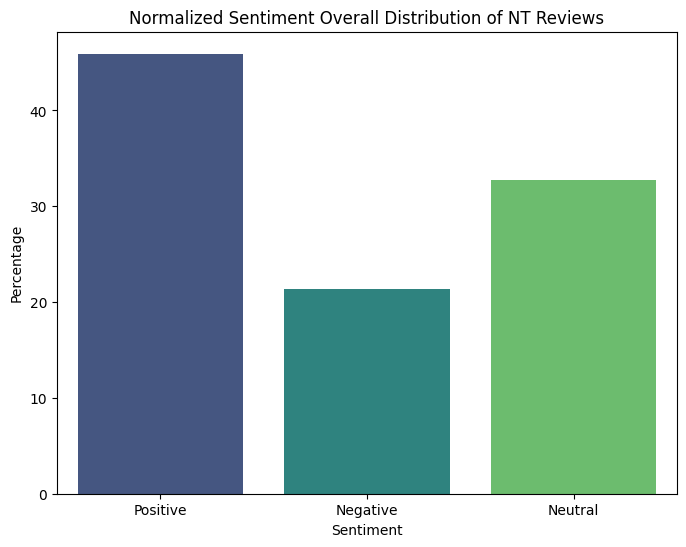

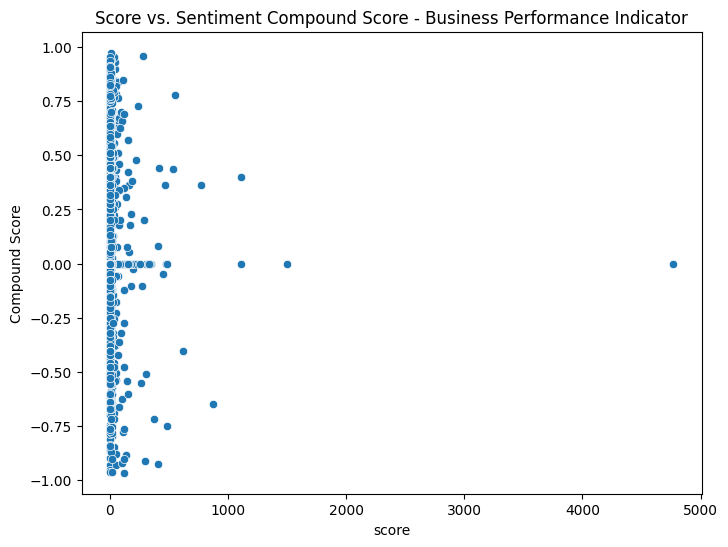

Average Compound Score (Overall Satisfaction): 0.14422486651411137

Top words related to Positive sentiments (Overall):
[('like', 105), ('one', 81), ('would', 63), ('dont', 62), ('people', 61), ('also', 60), ('darwin', 59), ('year', 56), ('time', 54), ('place', 54), ('day', 53), ('get', 52), ('im', 52), ('go', 50), ('lot', 45), ('well', 43), ('much', 43), ('think', 39), ('around', 39), ('thats', 38)]

Top words related to Negative sentiments (Overall):
[('people', 43), ('get', 39), ('one', 38), ('time', 30), ('day', 30), ('dont', 29), ('thats', 28), ('year', 28), ('im', 23), ('park', 22), ('also', 20), ('back', 20), ('would', 20), ('place', 20), ('right', 19), ('youre', 18), ('way', 18), ('many', 17), ('darwin', 17), ('alice', 17)]

Top words related to Neutral sentiments (Overall):
[('deleted', 32), ('one', 21), ('get', 20), ('dont', 19), ('australia', 19), ('day', 16), ('people', 14), ('back', 14), ('darwin', 14), ('croc', 13), ('think', 13), ('come', 13), ('removed', 13), ('there', 

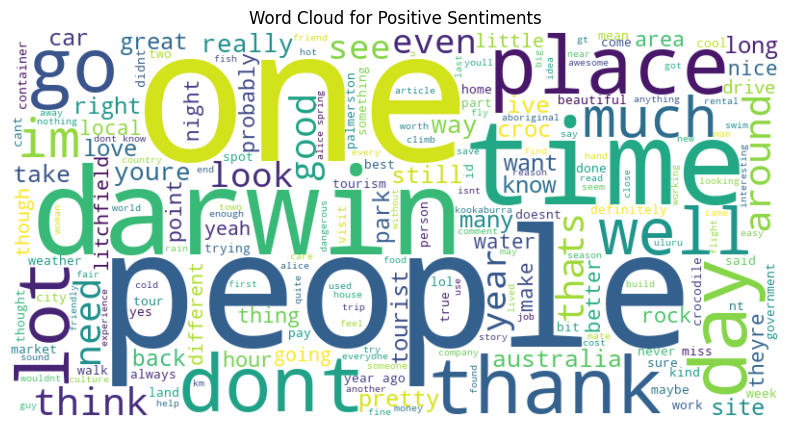

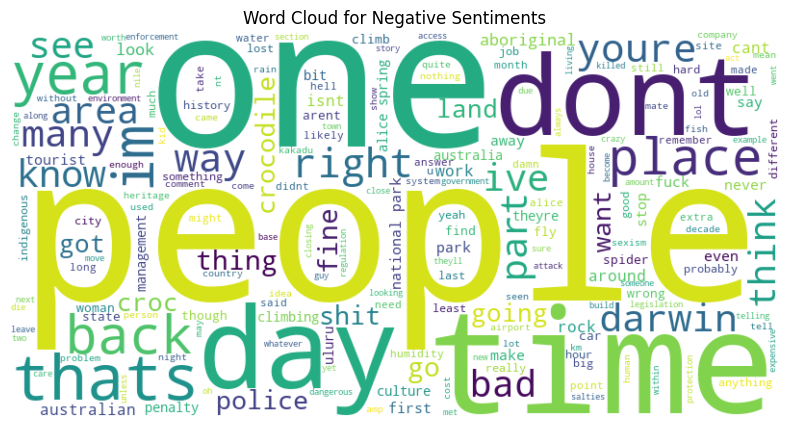

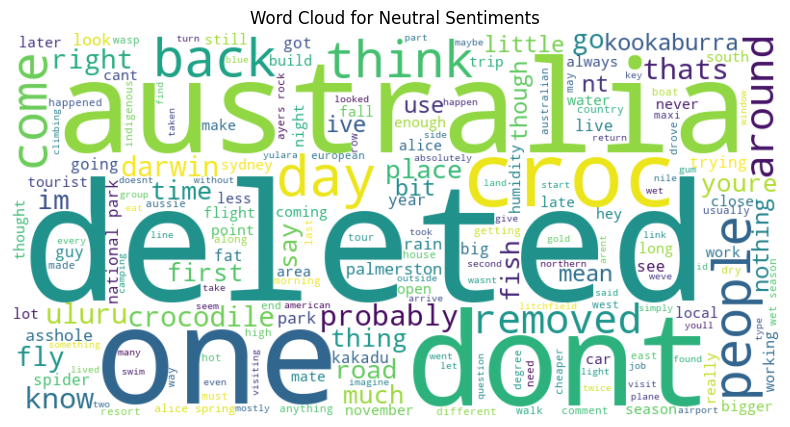


Sentiment Analysis Grouped by Region:
Average Compound Score by Region:
 region
Darwin                0.224608
Litchfield            0.191408
Katherine nt          0.175901
Uluru                 0.094597
Northern Territory    0.080714
Kakadu                0.077636
Name: Compound Score, dtype: float64
Sentiment Proportions (%) by Region:
 Sentiment            Negative    Neutral   Positive
region                                             
Darwin              17.667845  27.915194  54.416961
Kakadu              24.867725  34.920635  40.211640
Katherine nt        14.646465  41.414141  43.939394
Litchfield          19.323671  29.468599  51.207729
Northern Territory  26.666667  27.619048  45.714286
Uluru               27.857143  32.857143  39.285714


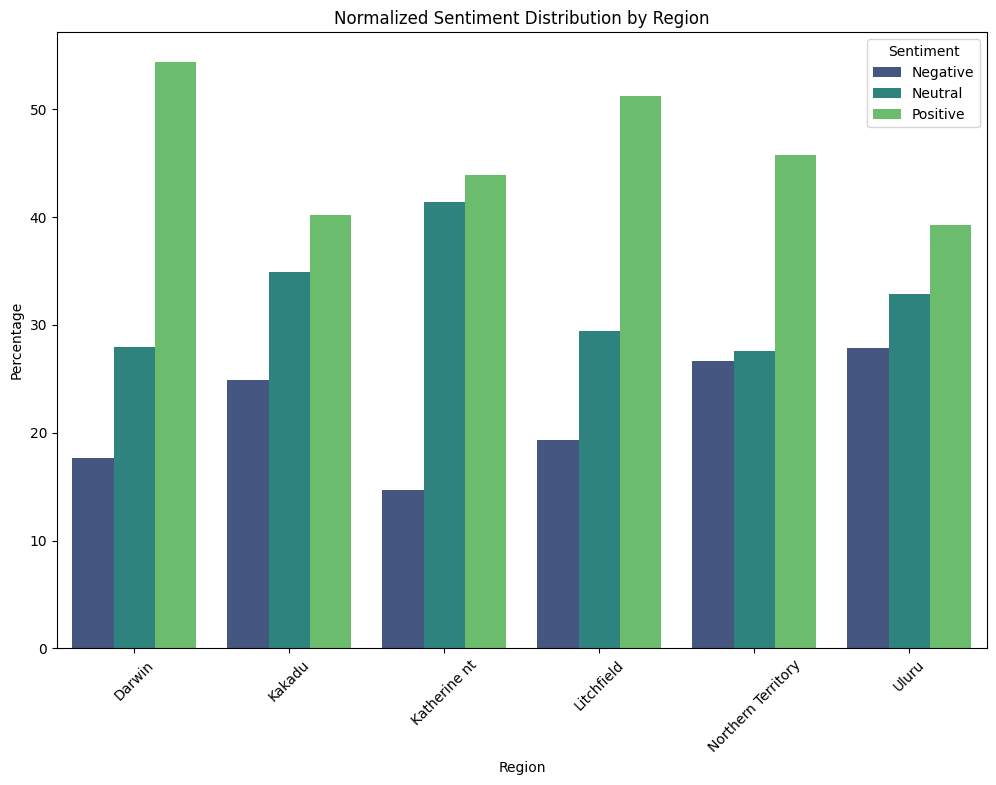

Average Rating by Region:
 region
Northern Territory    60.695238
Kakadu                49.261905
Katherine nt          22.979798
Uluru                 15.614286
Darwin                15.127208
Litchfield             8.830918
Name: score, dtype: float64


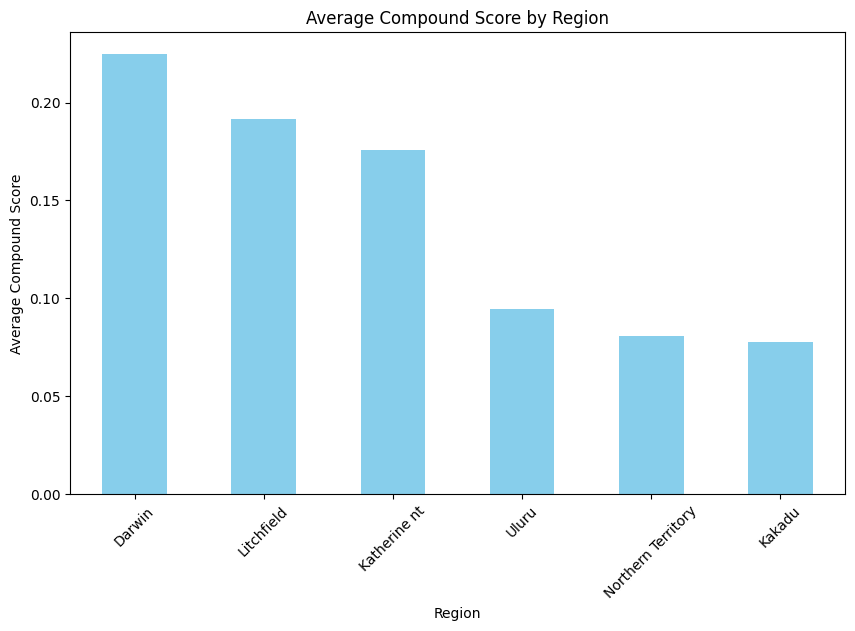


Top words for Kakadu:
Positive: [('like', 25), ('site', 22), ('people', 21), ('park', 21), ('dont', 17), ('australia', 17), ('im', 16), ('well', 15), ('get', 14), ('one', 14)]
Negative: [('bad', 14), ('people', 14), ('thats', 13), ('one', 12), ('land', 10), ('dont', 9), ('right', 9), ('year', 9), ('part', 9), ('kakadu', 9)]
Neutral: [('croc', 12), ('there', 10), ('dont', 8), ('deleted', 8), ('fish', 7), ('crocodile', 6), ('probably', 6), ('asshole', 6), ('fat', 6), ('australia', 5)]

Top words for Darwin:
Positive: [('darwin', 49), ('like', 31), ('day', 26), ('lot', 23), ('im', 23), ('place', 22), ('dont', 21), ('time', 21), ('year', 21), ('also', 20)]
Negative: [('darwin', 12), ('day', 11), ('get', 9), ('year', 9), ('ive', 7), ('got', 6), ('youre', 6), ('people', 6), ('km', 6), ('never', 5)]
Neutral: [('darwin', 8), ('know', 5), ('deleted', 5), ('get', 5), ('palmerston', 5), ('row', 4), ('crocodile', 4), ('dont', 4), ('season', 4), ('never', 4)]

Top words for Northern Territory:
Pos

In [4]:

# Part 1: Sentiment Analysis using VADER for Business Feedback
sia = SentimentIntensityAnalyzer()

def get_sentiment(text):
    scores = sia.polarity_scores(text)
    if scores['compound'] >= 0.05:
        return 'Positive'
    elif scores['compound'] <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['Sentiment'] = df['Processed Comment'].apply(get_sentiment)
df['Compound Score'] = df['Processed Comment'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Overall visualizations
# Visualize Sentiment Distribution - Key for identifying overall tourist satisfaction (normalized)
plt.figure(figsize=(8, 6))
sns.countplot(x='Sentiment', data=df, palette='viridis', stat='percent')
plt.title('Normalized Sentiment Overall Distribution of NT Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Percentage')
plt.show()

# Correlation between Rating and Compound Score - Helps correlate feedback with business ratings
plt.figure(figsize=(8, 6))
sns.scatterplot(x='score', y='Compound Score', data=df)
plt.title('Score vs. Sentiment Compound Score - Business Performance Indicator')
plt.show()

print("Average Compound Score (Overall Satisfaction):", df['Compound Score'].mean())

# Insightful analysis: Top words related to each sentiment (overall)
def get_top_words(sentiment_df, n=20):
    all_text = ' '.join(sentiment_df['Processed Comment'])
    words = all_text.split()
    word_counts = Counter(words)
    return word_counts.most_common(n)

positive_df = df[df['Sentiment'] == 'Positive']
negative_df = df[df['Sentiment'] == 'Negative']
neutral_df = df[df['Sentiment'] == 'Neutral']

print("\nTop words related to Positive sentiments (Overall):")
print(get_top_words(positive_df))

print("\nTop words related to Negative sentiments (Overall):")
print(get_top_words(negative_df))

print("\nTop words related to Neutral sentiments (Overall):")
print(get_top_words(neutral_df))

# Word clouds for sentiments
def generate_wordcloud(text, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(title)
    plt.axis('off')
    plt.show()

generate_wordcloud(' '.join(positive_df['Processed Comment']), 'Word Cloud for Positive Sentiments')
generate_wordcloud(' '.join(negative_df['Processed Comment']), 'Word Cloud for Negative Sentiments')
generate_wordcloud(' '.join(neutral_df['Processed Comment']), 'Word Cloud for Neutral Sentiments')

# Group by region
print("\nSentiment Analysis Grouped by Region:")

# Average Compound Score by Region
avg_score_region = df.groupby('region')['Compound Score'].mean().sort_values(ascending=False)
print("Average Compound Score by Region:\n", avg_score_region)

# Sentiment Proportions by Region
sentiment_counts_region = df.groupby(['region', 'Sentiment']).size().unstack(fill_value=0)
sentiment_proportions_region = sentiment_counts_region.div(sentiment_counts_region.sum(axis=1), axis=0) * 100
print("Sentiment Proportions (%) by Region:\n", sentiment_proportions_region)

# Visualize Normalized Sentiment Distribution by Region (using barplot for proper per-group normalization)
sentiment_proportions_region_reset = sentiment_proportions_region.reset_index().melt(id_vars='region', var_name='Sentiment', value_name='Percentage')
plt.figure(figsize=(12, 8))
sns.barplot(x='region', y='Percentage', hue='Sentiment', data=sentiment_proportions_region_reset, palette='viridis')
plt.title('Normalized Sentiment Distribution by Region')
plt.xlabel('Region')
plt.ylabel('Percentage')
plt.xticks(rotation=45)
plt.legend(title='Sentiment')
plt.show()

# Average Rating by Region
avg_rating_region = df.groupby('region')['score'].mean().sort_values(ascending=False)
print("Average Rating by Region:\n", avg_rating_region)

# Visualize Average Compound Score by Region
plt.figure(figsize=(10, 6))
avg_score_region.plot(kind='bar', color='skyblue')
plt.title('Average Compound Score by Region')
plt.xlabel('Region')
plt.ylabel('Average Compound Score')
plt.xticks(rotation=45)
plt.show()

# Insightful analysis: Top words by sentiment for each region
unique_regions = df['region'].unique()
for region in unique_regions:
    region_df = df[df['region'] == region]
    positive_region = region_df[region_df['Sentiment'] == 'Positive']
    negative_region = region_df[region_df['Sentiment'] == 'Negative']
    neutral_region = region_df[region_df['Sentiment'] == 'Neutral']
    
    print(f"\nTop words for {region}:")
    print("Positive:", get_top_words(positive_region, n=10))
    print("Negative:", get_top_words(negative_region, n=10))
    print("Neutral:", get_top_words(neutral_region, n=10))



# Create Output directory if it doesn't exist
os.makedirs('Output', exist_ok=True)

# Export statistics to file
output_file = 'Output/reddit_sentiment_analysis.txt'
with open(output_file, 'w', encoding='utf-8') as f:
    f.write("Reddit Comment Sentiment Analysis Statistics\n")
    f.write("=" * 50 + "\n\n")
    
    f.write("Data Summary:\n")
    f.write(f"Total Comments: {df.shape[0]}\n")
    f.write(f"Average Compound Score (Overall Satisfaction): {df['Compound Score'].mean():.4f}\n\n")
    
    f.write("Sentiment Distribution (Overall):\n")
    sentiment_counts = df['Sentiment'].value_counts(normalize=True) * 100
    for sentiment, percentage in sentiment_counts.items():
        f.write(f"{sentiment}: {percentage:.2f}%\n")
    f.write("\n")
    
    f.write("Top Words by Sentiment (Overall):\n")
    f.write("Positive:\n")
    for word, count in get_top_words(positive_df):
        f.write(f"  {word}: {count}\n")
    f.write("\nNegative:\n")
    for word, count in get_top_words(negative_df):
        f.write(f"  {word}: {count}\n")
    f.write("\nNeutral:\n")
    for word, count in get_top_words(neutral_df):
        f.write(f"  {word}: {count}\n")
    f.write("\n")
    
    f.write("Sentiment Analysis by Region:\n")
    avg_score_region = df.groupby('region')['Compound Score'].mean().sort_values(ascending=False)
    f.write("Average Compound Score by Region:\n")
    for region, score in avg_score_region.items():
        f.write(f"{region}: {score:.4f}\n")
    f.write("\n")
    
    sentiment_counts_region = df.groupby(['region', 'Sentiment']).size().unstack(fill_value=0)
    sentiment_proportions_region = sentiment_counts_region.div(sentiment_counts_region.sum(axis=1), axis=0) * 100
    f.write("Sentiment Proportions (%) by Region:\n")
    for region in sentiment_proportions_region.index:
        f.write(f"{region}:\n")
        for sentiment in sentiment_proportions_region.columns:
            f.write(f"  {sentiment}: {sentiment_proportions_region.loc[region, sentiment]:.2f}%\n")
    f.write("\n")
    
    avg_rating_region = df.groupby('region')['score'].mean().sort_values(ascending=False)
    f.write("Average Score by Region:\n")
    for region, rating in avg_rating_region.items():
        f.write(f"{region}: {rating:.4f}\n")
    f.write("\n")
    
    f.write("Top Words by Sentiment for Each Region:\n")
    unique_regions = df['region'].unique()
    for region in sorted(unique_regions):
        region_df = df[df['region'] == region]
        positive_region = region_df[region_df['Sentiment'] == 'Positive']
        negative_region = region_df[region_df['Sentiment'] == 'Negative']
        neutral_region = region_df[region_df['Sentiment'] == 'Neutral']
        f.write(f"{region}:\n")
        f.write("  Positive:\n")
        for word, count in get_top_words(positive_region, n=10):
            f.write(f"    {word}: {count}\n")
        f.write("  Negative:\n")
        for word, count in get_top_words(negative_region, n=10):
            f.write(f"    {word}: {count}\n")
        f.write("  Neutral:\n")
        for word, count in get_top_words(neutral_region, n=10):
            f.write(f"    {word}: {count}\n")
        f.write("\n")

print(f"Sentiment analysis statistics exported to {output_file}")




/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_71747/1612694480.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_time['Month_Year'] = df_time['date'].dt.to_period('M')


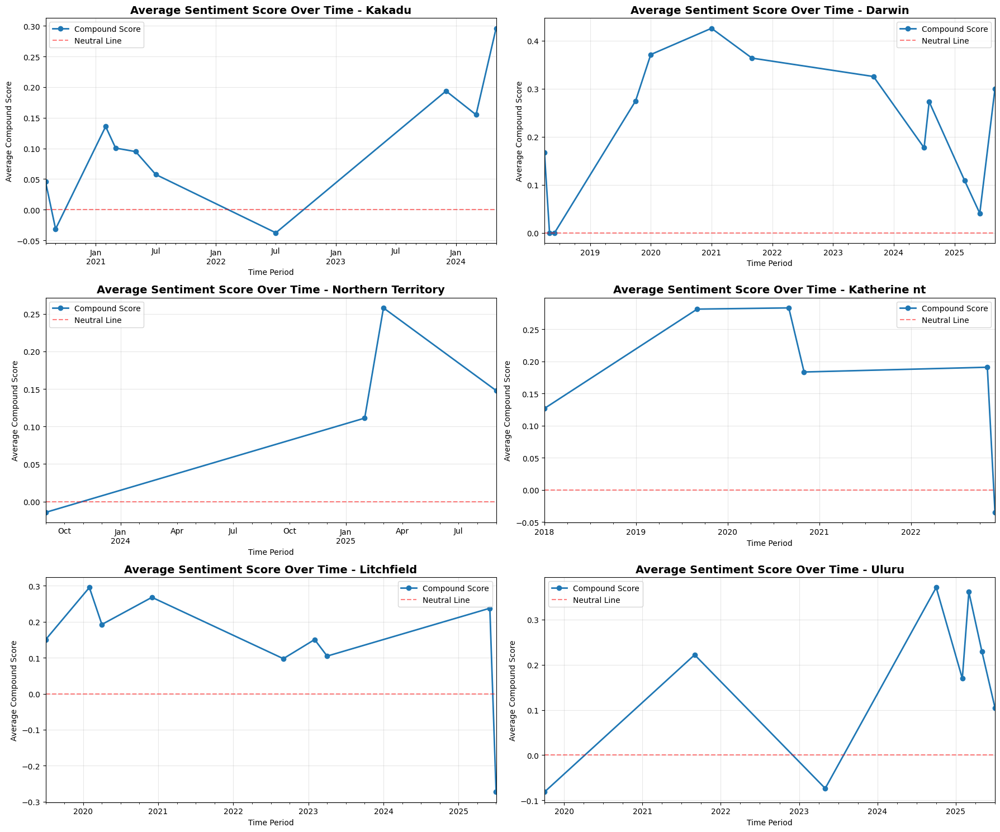

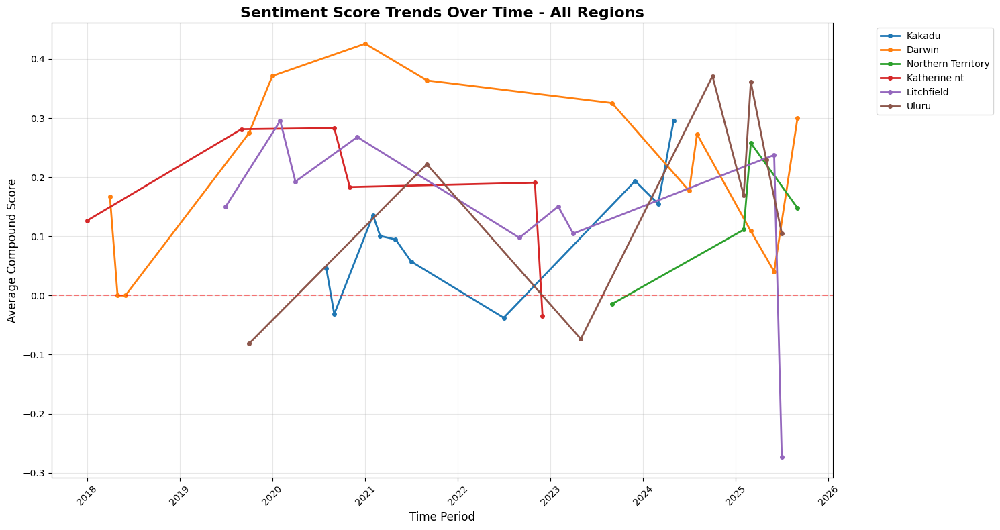

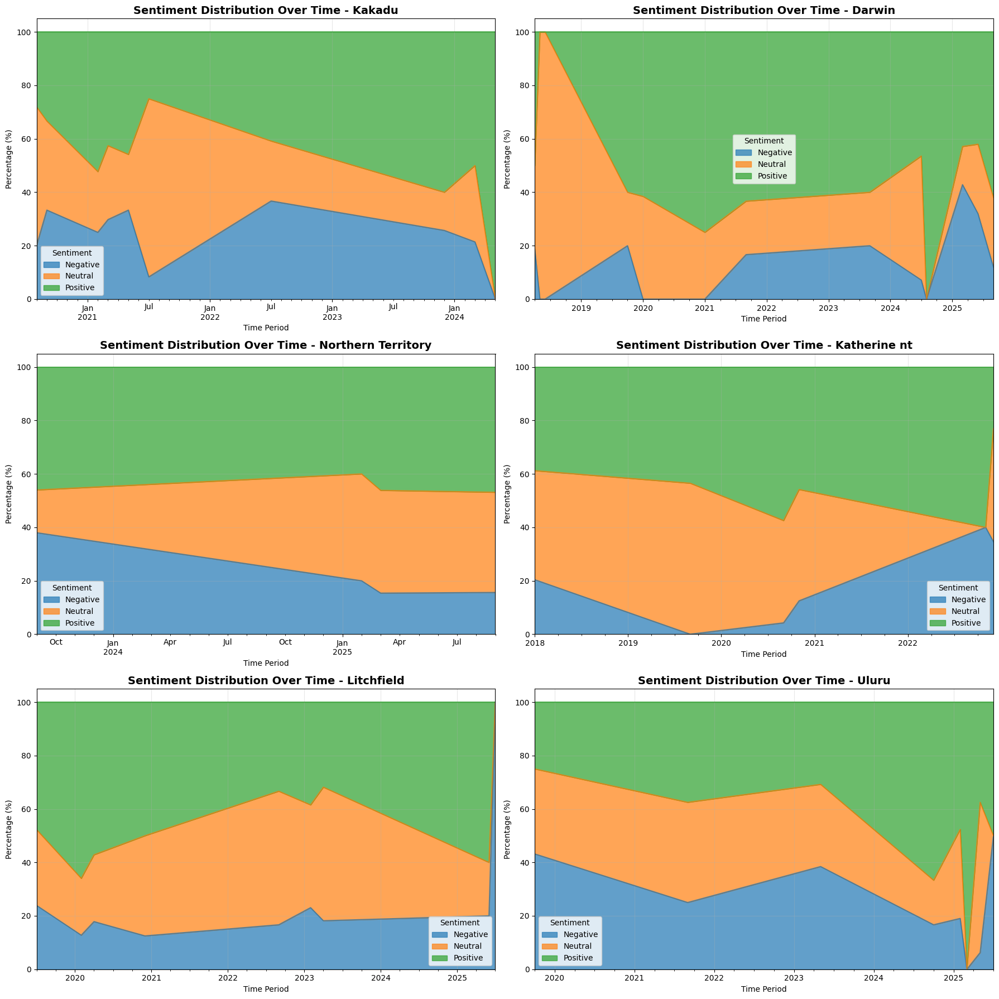

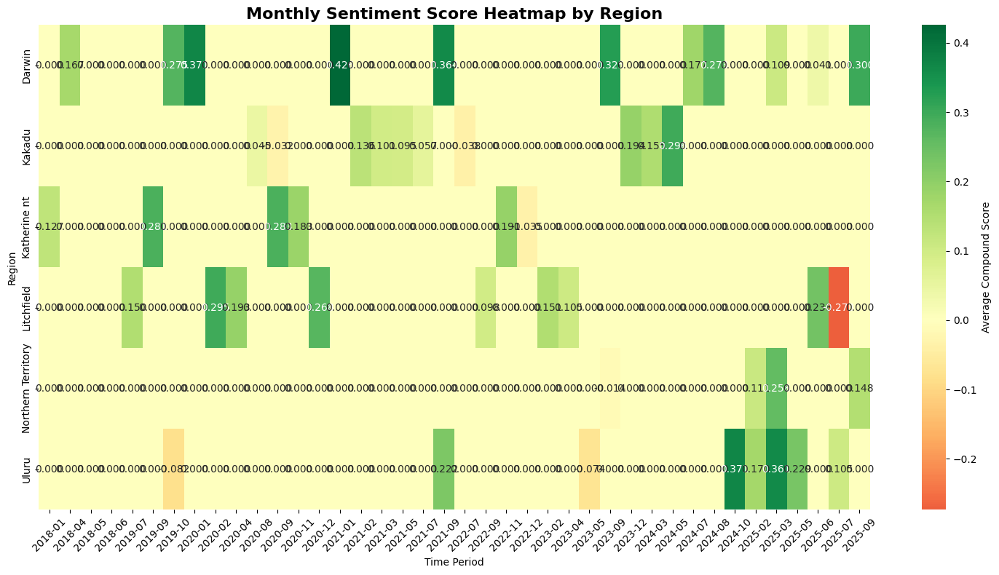

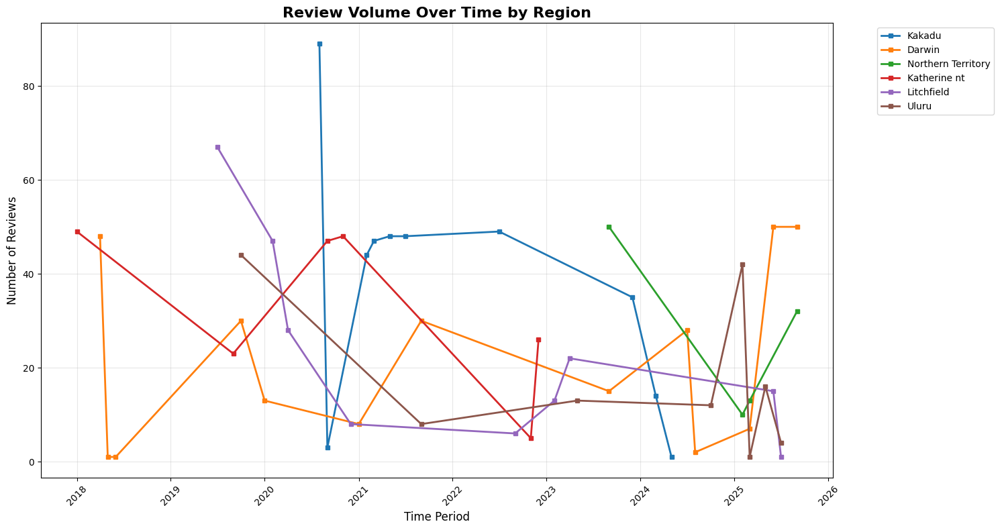

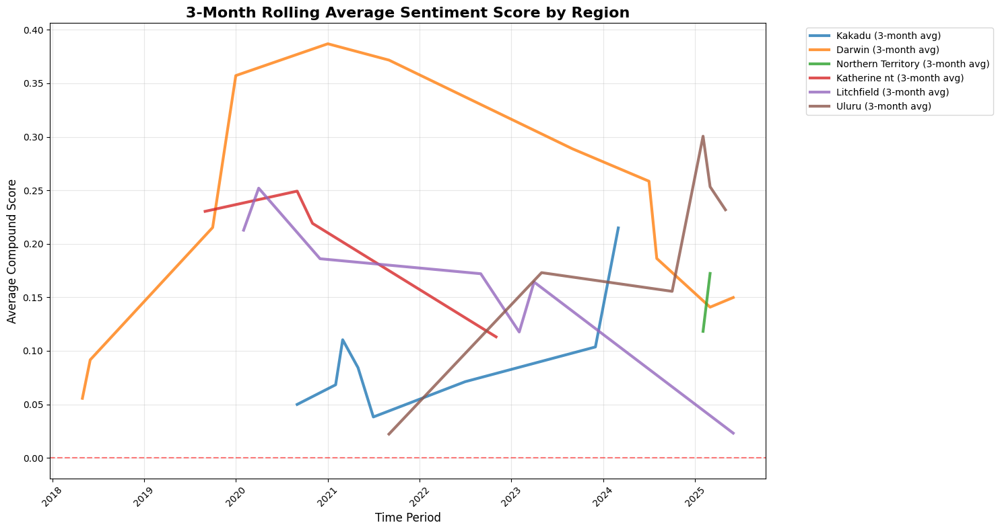


TIME-BASED SENTIMENT ANALYSIS SUMMARY BY REGION

KAKADU:
 Average Sentiment Score: 0.101
 Sentiment Volatility (Std Dev): 0.101
 Best Month: 2024-05 (0.296)
 Worst Month: 2022-07 (-0.038)
 Total Months Tracked: 10
 Months with Positive Sentiment: 7
 Months with Negative Sentiment: 0

DARWIN:
 Average Sentiment Score: 0.217
 Sentiment Volatility (Std Dev): 0.146
 Best Month: 2021-01 (0.426)
 Worst Month: 2018-05 (0.000)
 Total Months Tracked: 13
 Months with Positive Sentiment: 10
 Months with Negative Sentiment: 0

NORTHERN TERRITORY:
 Average Sentiment Score: 0.126
 Sentiment Volatility (Std Dev): 0.112
 Best Month: 2025-03 (0.258)
 Worst Month: 2023-09 (-0.014)
 Total Months Tracked: 4
 Months with Positive Sentiment: 3
 Months with Negative Sentiment: 0

KATHERINE NT:
 Average Sentiment Score: 0.172
 Sentiment Volatility (Std Dev): 0.118
 Best Month: 2020-09 (0.283)
 Worst Month: 2022-12 (-0.035)
 Total Months Tracked: 6
 Months with Positive Sentiment: 5
 Months with Negative Sent

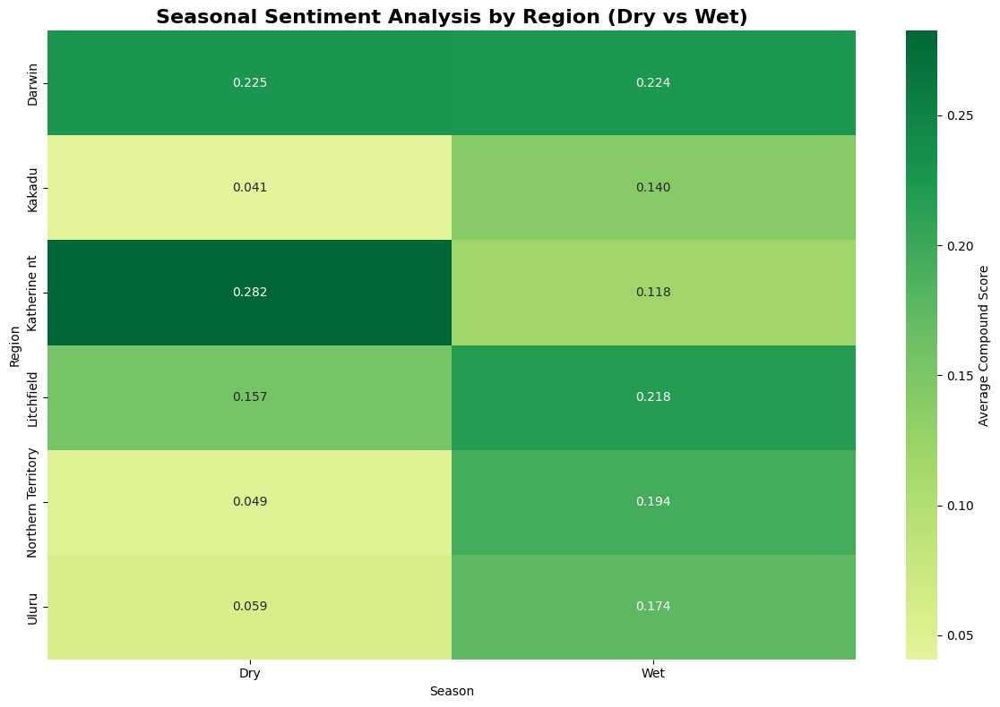


Seasonal Sentiment Summary (Dry vs Wet):
Season                Dry    Wet
region                          
Darwin              0.225  0.224
Kakadu              0.041  0.140
Katherine nt        0.282  0.118
Litchfield          0.157  0.218
Northern Territory  0.049  0.194
Uluru               0.059  0.174
Time-based sentiment analysis statistics exported to Output/reddit_time_sentiment_analysis.txt


In [5]:
# Convert date column to datetime
df_time = df.dropna(subset=['date']).copy()
df_time['Month_Year'] = df_time['date'].dt.to_period('M')

# Time-based Sentiment Analysis by Region
# 1. Sentiment Score Trends Over Time by Region
regions = df_time['region'].unique()
n_regions = len(regions)
n_cols = 2
n_rows = (n_regions + 1) // 2
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
axes = axes.flatten() if n_regions > 1 else [axes]
for i, region in enumerate(regions):
    region_data = df_time[df_time['region'] == region]
    monthly_sentiment = region_data.groupby('Month_Year')['Compound Score'].mean()
    ax = axes[i]
    monthly_sentiment.plot(ax=ax, marker='o', linewidth=2, markersize=6)
    ax.set_title(f'Average Sentiment Score Over Time - {region}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Time Period')
    ax.set_ylabel('Average Compound Score')
    ax.grid(True, alpha=0.3)
    ax.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Neutral Line')
    ax.legend()
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.show()

# 2. Combined Time Series Plot for All Regions
plt.figure(figsize=(15, 8))
for region in regions:
    region_data = df_time[df_time['region'] == region]
    monthly_sentiment = region_data.groupby('Month_Year')['Compound Score'].mean()
    plt.plot(monthly_sentiment.index.to_timestamp(), monthly_sentiment.values,
             marker='o', linewidth=2, markersize=4, label=region)
plt.title('Sentiment Score Trends Over Time - All Regions', fontsize=16, fontweight='bold')
plt.xlabel('Time Period', fontsize=12)
plt.ylabel('Average Compound Score', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Neutral Line')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Sentiment Category Distribution Over Time by Region
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 6*n_rows))
axes = axes.flatten() if n_regions > 1 else [axes]
for i, region in enumerate(regions):
    region_data = df_time[df_time['region'] == region]
    sentiment_time = region_data.groupby(['Month_Year', 'Sentiment']).size().unstack(fill_value=0)
    sentiment_proportions = sentiment_time.div(sentiment_time.sum(axis=1), axis=0) * 100
    ax = axes[i]
    sentiment_proportions.plot(kind='area', ax=ax, alpha=0.7, stacked=True)
    ax.set_title(f'Sentiment Distribution Over Time - {region}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Time Period')
    ax.set_ylabel('Percentage (%)')
    ax.legend(title='Sentiment')
    ax.grid(True, alpha=0.3)
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.show()

# 4. Heatmap of Monthly Sentiment Scores by Region
monthly_data = df_time.groupby(['Month_Year', 'region'])['Compound Score'].mean().unstack(fill_value=0)
plt.figure(figsize=(15, 8))
sns.heatmap(monthly_data.T, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
            cbar_kws={'label': 'Average Compound Score'})
plt.title('Monthly Sentiment Score Heatmap by Region', fontsize=16, fontweight='bold')
plt.xlabel('Time Period')
plt.ylabel('Region')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. Volume of Reviews Over Time by Region
plt.figure(figsize=(15, 8))
for region in regions:
    region_data = df_time[df_time['region'] == region]
    monthly_volume = region_data.groupby('Month_Year').size()
    plt.plot(monthly_volume.index.to_timestamp(), monthly_volume.values,
             marker='s', linewidth=2, markersize=4, label=region)
plt.title('Review Volume Over Time by Region', fontsize=16, fontweight='bold')
plt.xlabel('Time Period', fontsize=12)
plt.ylabel('Number of Reviews', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. Rolling Average Sentiment (3-month window)
plt.figure(figsize=(15, 8))
for region in regions:
    region_data = df_time[df_time['region'] == region]
    monthly_sentiment = region_data.groupby('Month_Year')['Compound Score'].mean()
    rolling_avg = monthly_sentiment.rolling(window=3, center=True).mean()
    plt.plot(rolling_avg.index.to_timestamp(), rolling_avg.values,
             linewidth=3, label=f'{region} (3-month avg)', alpha=0.8)
plt.title('3-Month Rolling Average Sentiment Score by Region', fontsize=16, fontweight='bold')
plt.xlabel('Time Period', fontsize=12)
plt.ylabel('Average Compound Score', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. Statistical Summary Table
print("\n" + "="*80)
print("TIME-BASED SENTIMENT ANALYSIS SUMMARY BY REGION")
print("="*80)
for region in regions:
    region_data = df_time[df_time['region'] == region]
    monthly_sentiment = region_data.groupby('Month_Year')['Compound Score'].mean()
    print(f"\n{region.upper()}:")
    print(f" Average Sentiment Score: {monthly_sentiment.mean():.3f}")
    print(f" Sentiment Volatility (Std Dev): {monthly_sentiment.std():.3f}")
    print(f" Best Month: {monthly_sentiment.idxmax()} ({monthly_sentiment.max():.3f})")
    print(f" Worst Month: {monthly_sentiment.idxmin()} ({monthly_sentiment.min():.3f})")
    print(f" Total Months Tracked: {len(monthly_sentiment)}")
    print(f" Months with Positive Sentiment: {(monthly_sentiment > 0.05).sum()}")
    print(f" Months with Negative Sentiment: {(monthly_sentiment < -0.05).sum()}")

# 8. Seasonal Analysis (Dry and Wet Seasons)
df_time['Month'] = df_time['date'].dt.month
df_time['Season'] = df_time['Month'].map({
    5: 'Dry', 6: 'Dry', 7: 'Dry', 8: 'Dry', 9: 'Dry', 10: 'Dry',  # May to October
    11: 'Wet', 12: 'Wet', 1: 'Wet', 2: 'Wet', 3: 'Wet', 4: 'Wet'   # November to April
})
seasonal_sentiment = df_time.groupby(['region', 'Season'])['Compound Score'].mean().unstack(fill_value=0)
plt.figure(figsize=(12, 8))
sns.heatmap(seasonal_sentiment, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
            cbar_kws={'label': 'Average Compound Score'})
plt.title('Seasonal Sentiment Analysis by Region (Dry vs Wet)', fontsize=16, fontweight='bold')
plt.xlabel('Season')
plt.ylabel('Region')
plt.tight_layout()
plt.show()
print("\nSeasonal Sentiment Summary (Dry vs Wet):")
print(seasonal_sentiment.round(3))



# Export statistics to file
output_file = 'Output/reddit_time_sentiment_analysis.txt'
with open(output_file, 'w', encoding='utf-8') as f:
    f.write("Time-Based Sentiment Analysis Statistics\n")
    f.write("=" * 80 + "\n\n")
    
    f.write("Sentiment Score Trends by Region:\n")
    for region in regions:
        region_data = df_time[df_time['region'] == region]
        monthly_sentiment = region_data.groupby('Month_Year')['Compound Score'].mean()
        f.write(f"\n{region.upper()}:\n")
        f.write("Monthly Average Sentiment Scores:\n")
        for month_year, score in monthly_sentiment.items():
            f.write(f"  {month_year}: {score:.3f}\n")
        f.write("\n")
    
    f.write("Sentiment Category Distribution by Region:\n")
    for region in regions:
        region_data = df_time[df_time['region'] == region]
        sentiment_time = region_data.groupby(['Month_Year', 'Sentiment']).size().unstack(fill_value=0)
        sentiment_proportions = sentiment_time.div(sentiment_time.sum(axis=1), axis=0) * 100
        f.write(f"\n{region.upper()} Sentiment Proportions (%):\n")
        for month_year in sentiment_proportions.index:
            f.write(f"  {month_year}:\n")
            for sentiment in sentiment_proportions.columns:
                f.write(f"    {sentiment}: {sentiment_proportions.loc[month_year, sentiment]:.2f}%\n")
        f.write("\n")
    
    f.write("Monthly Sentiment Scores by Region (Heatmap Data):\n")
    monthly_data = df_time.groupby(['Month_Year', 'region'])['Compound Score'].mean().unstack(fill_value=0)
    f.write(monthly_data.round(3).to_string() + "\n\n")
    
    f.write("Review Volume by Region:\n")
    for region in regions:
        region_data = df_time[df_time['region'] == region]
        monthly_volume = region_data.groupby('Month_Year').size()
        f.write(f"\n{region.upper()}:\n")
        for month_year, count in monthly_volume.items():
            f.write(f"  {month_year}: {count} reviews\n")
        f.write("\n")
    
    f.write("Rolling Average Sentiment (3-Month Window):\n")
    for region in regions:
        region_data = df_time[df_time['region'] == region]
        monthly_sentiment = region_data.groupby('Month_Year')['Compound Score'].mean()
        rolling_avg = monthly_sentiment.rolling(window=3, center=True).mean()
        f.write(f"\n{region.upper()}:\n")
        for month_year, score in rolling_avg.items():
            if pd.notna(score):
                f.write(f"  {month_year}: {score:.3f}\n")
        f.write("\n")
    
    f.write("=" * 80 + "\n")
    f.write("TIME-BASED SENTIMENT ANALYSIS SUMMARY BY REGION\n")
    f.write("=" * 80 + "\n")
    for region in regions:
        region_data = df_time[df_time['region'] == region]
        monthly_sentiment = region_data.groupby('Month_Year')['Compound Score'].mean()
        f.write(f"\n{region.upper()}:\n")
        f.write(f"  Average Sentiment Score: {monthly_sentiment.mean():.3f}\n")
        f.write(f"  Sentiment Volatility (Std Dev): {monthly_sentiment.std():.3f}\n")
        f.write(f"  Best Month: {monthly_sentiment.idxmax()} ({monthly_sentiment.max():.3f})\n")
        f.write(f"  Worst Month: {monthly_sentiment.idxmin()} ({monthly_sentiment.min():.3f})\n")
        f.write(f"  Total Months Tracked: {len(monthly_sentiment)}\n")
        f.write(f"  Months with Positive Sentiment: {(monthly_sentiment > 0.05).sum()}\n")
        f.write(f"  Months with Negative Sentiment: {(monthly_sentiment < -0.05).sum()}\n")
    
    f.write("\nSeasonal Sentiment Analysis (Dry vs Wet):\n")
    df_time['Month'] = df_time['date'].dt.month
    df_time['Season'] = df_time['Month'].map({
        5: 'Dry', 6: 'Dry', 7: 'Dry', 8: 'Dry', 9: 'Dry', 10: 'Dry',
        11: 'Wet', 12: 'Wet', 1: 'Wet', 2: 'Wet', 3: 'Wet', 4: 'Wet'
    })
    seasonal_sentiment = df_time.groupby(['region', 'Season'])['Compound Score'].mean().unstack(fill_value=0)
    f.write(seasonal_sentiment.round(3).to_string())

print(f"Time-based sentiment analysis statistics exported to {output_file}")

Global Top Topics:
Topic 0: 0.013*"one" + 0.009*"day" + 0.006*"ive" + 0.006*"like" + 0.005*"kookaburra" + 0.005*"darwin" + 0.005*"thanks" + 0.005*"get" + 0.005*"much" + 0.004*"also"
Topic 1: 0.007*"park" + 0.007*"way" + 0.006*"one" + 0.005*"people" + 0.005*"dont" + 0.005*"like" + 0.005*"time" + 0.005*"around" + 0.005*"year" + 0.005*"bit"
Topic 2: 0.010*"deleted" + 0.006*"one" + 0.006*"dont" + 0.005*"site" + 0.005*"get" + 0.005*"come" + 0.005*"im" + 0.005*"time" + 0.005*"lot" + 0.004*"youre"
Topic 3: 0.009*"people" + 0.009*"would" + 0.008*"like" + 0.006*"im" + 0.006*"australia" + 0.006*"year" + 0.006*"get" + 0.006*"one" + 0.005*"darwin" + 0.005*"also"
Topic 4: 0.008*"dont" + 0.007*"go" + 0.006*"alice" + 0.006*"place" + 0.005*"know" + 0.005*"time" + 0.005*"season" + 0.005*"thats" + 0.005*"get" + 0.004*"there"


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_71747/3947715984.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


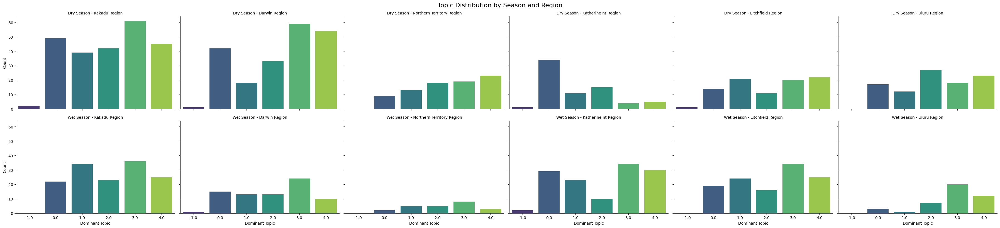

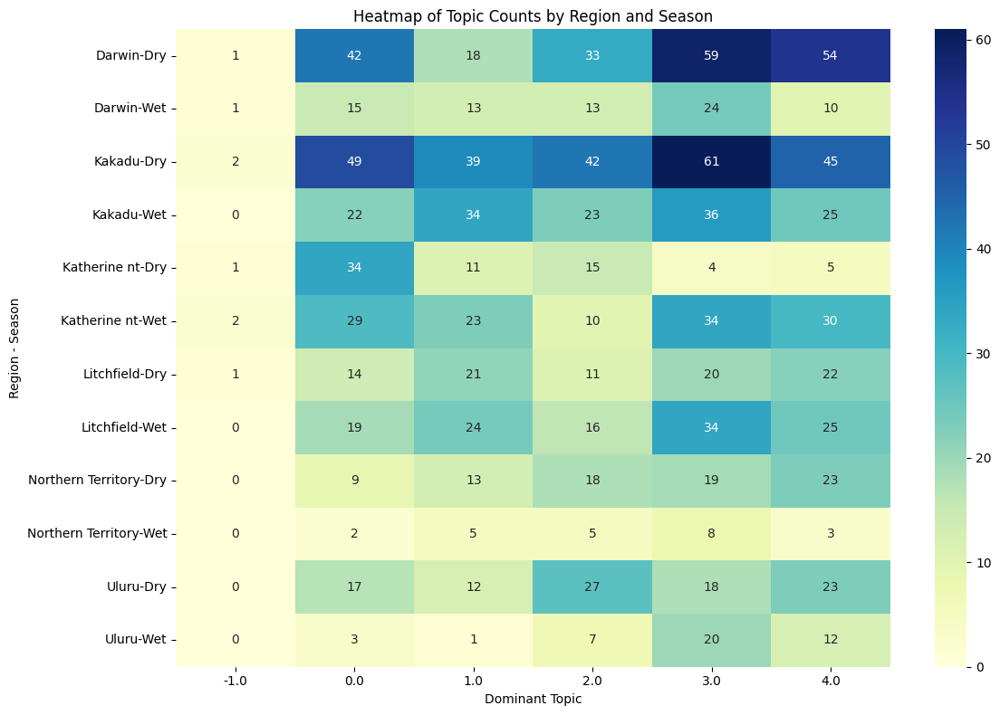


Processing Kakadu - Dry (236 comments)
Top Topics for Kakadu - Dry:
Topic 0: 0.011*"he" + 0.010*"asshole" + 0.010*"get" + 0.009*"park" + 0.008*"crocodile" + 0.008*"site" + 0.008*"people" + 0.008*"think" + 0.008*"fat" + 0.008*"away"
Topic 1: 0.011*"dont" + 0.010*"croc" + 0.008*"park" + 0.008*"right" + 0.007*"australia" + 0.006*"fish" + 0.006*"people" + 0.006*"said" + 0.006*"quote" + 0.006*"article"
Topic 2: 0.011*"like" + 0.008*"park" + 0.008*"one" + 0.007*"site" + 0.007*"well" + 0.007*"dont" + 0.007*"croc" + 0.005*"caught" + 0.005*"thing" + 0.005*"gender"
Topic 3: 0.019*"fish" + 0.010*"crocodile" + 0.009*"sure" + 0.009*"right" + 0.009*"one" + 0.008*"youre" + 0.008*"crocs" + 0.008*"track" + 0.007*"bigger" + 0.007*"im"
Topic 4: 0.018*"croc" + 0.012*"deleted" + 0.009*"mean" + 0.009*"aboriginal" + 0.009*"dont" + 0.007*"probably" + 0.007*"one" + 0.007*"im" + 0.007*"also" + 0.007*"culture"

Processing Kakadu - Wet (140 comments)
Top Topics for Kakadu - Wet:
Topic 0: 0.010*"people" + 0.008*"

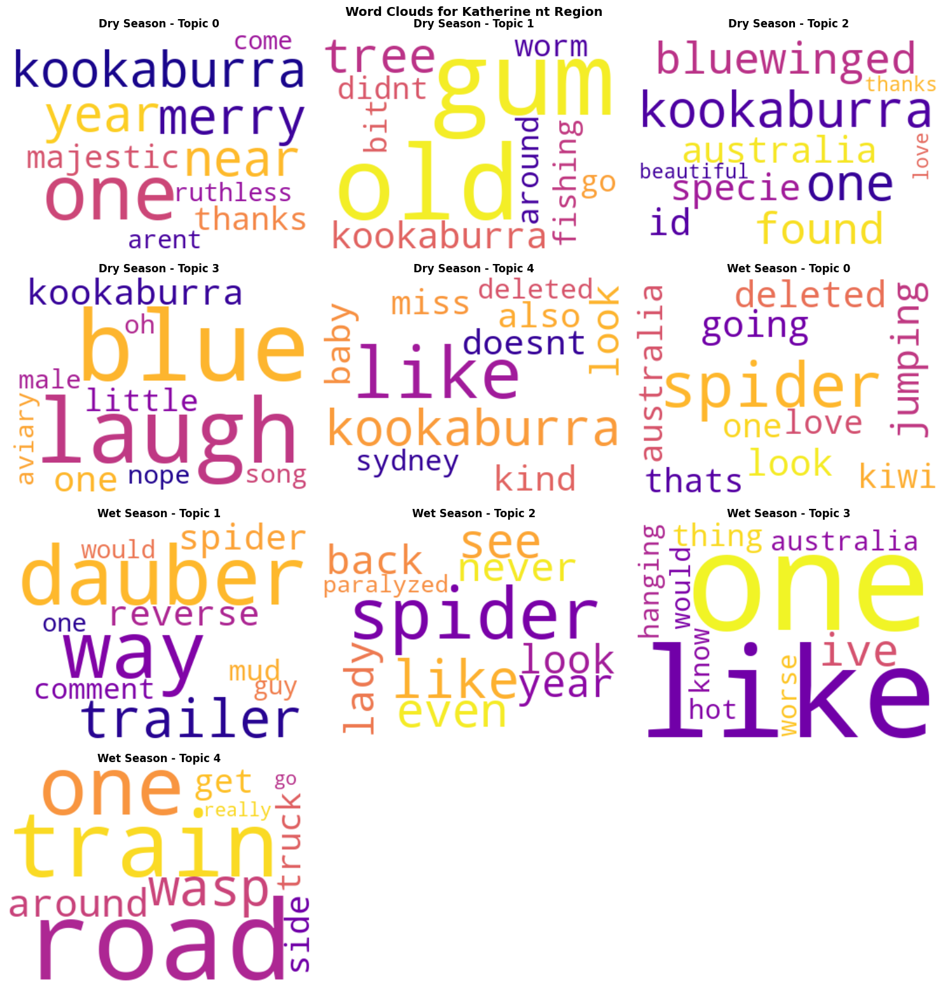

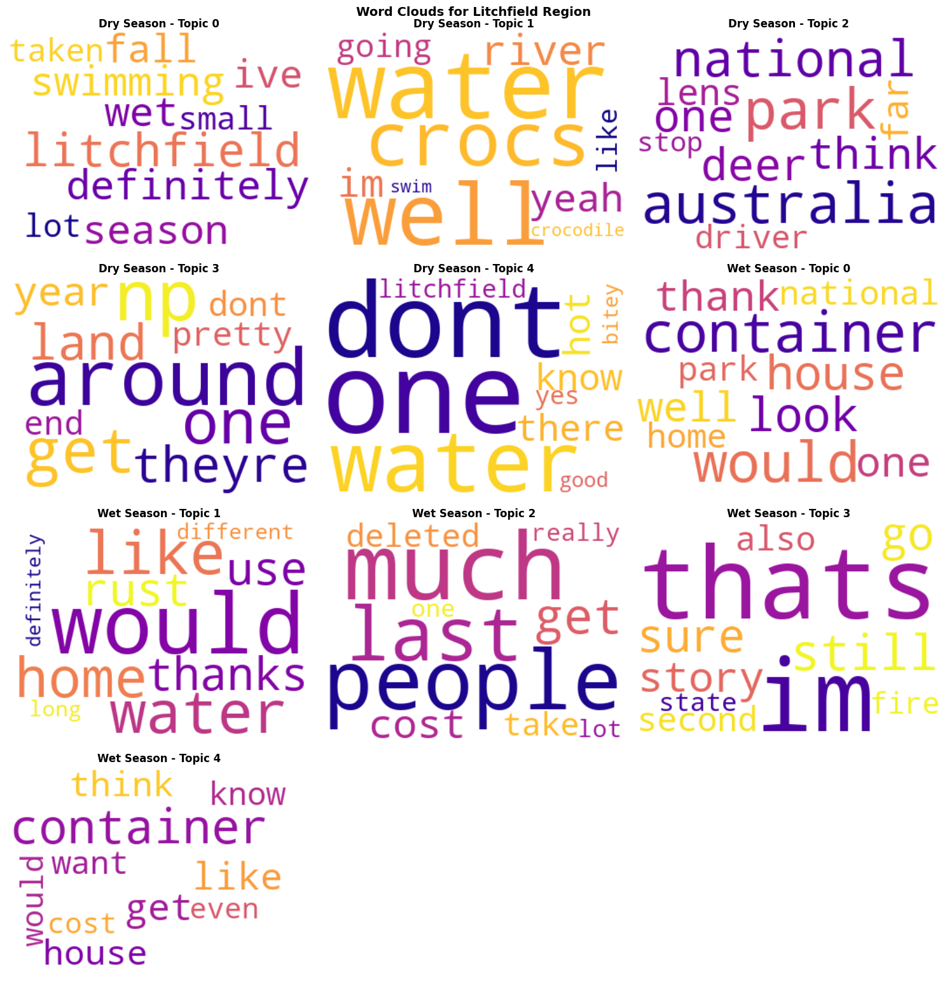

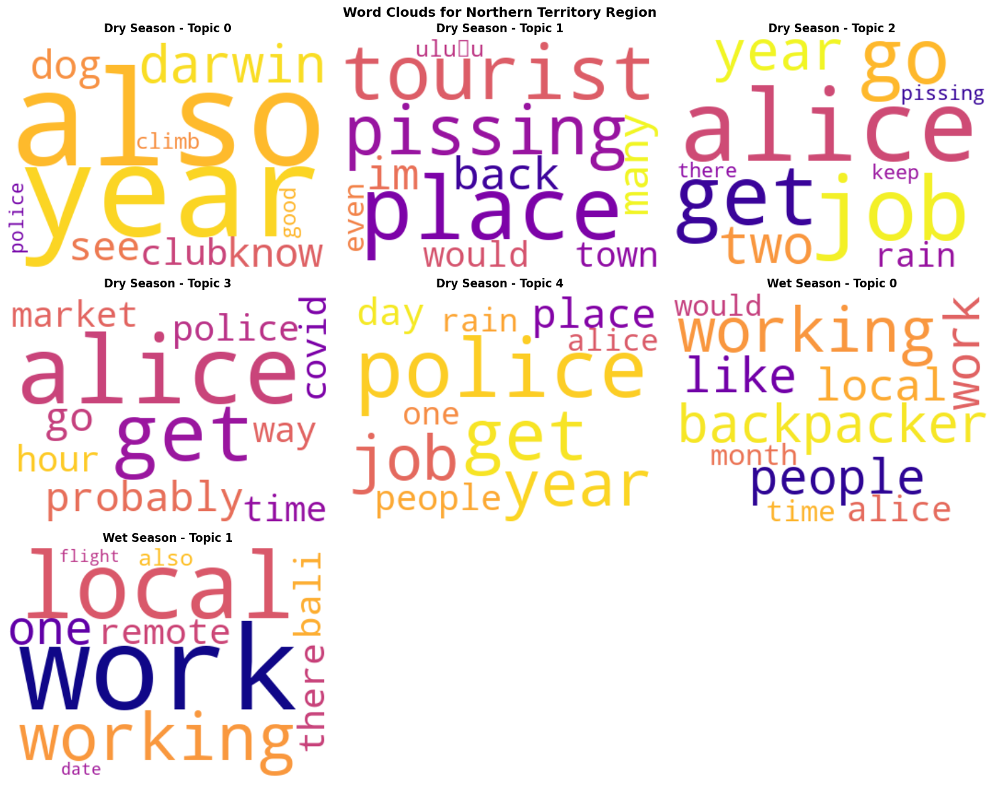

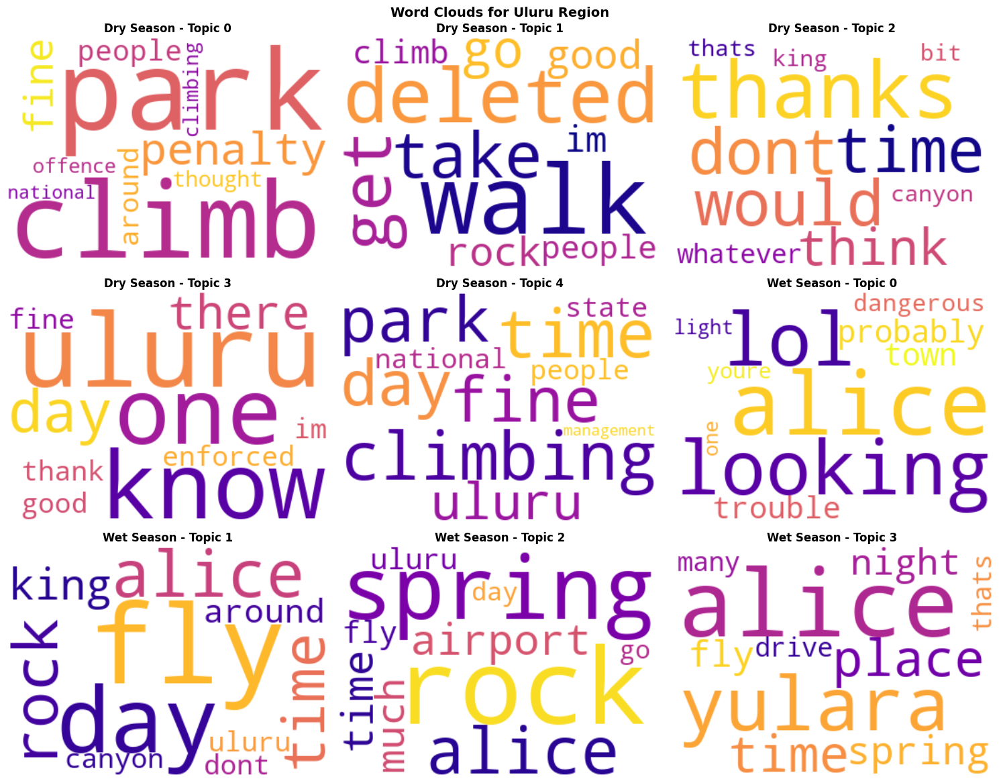

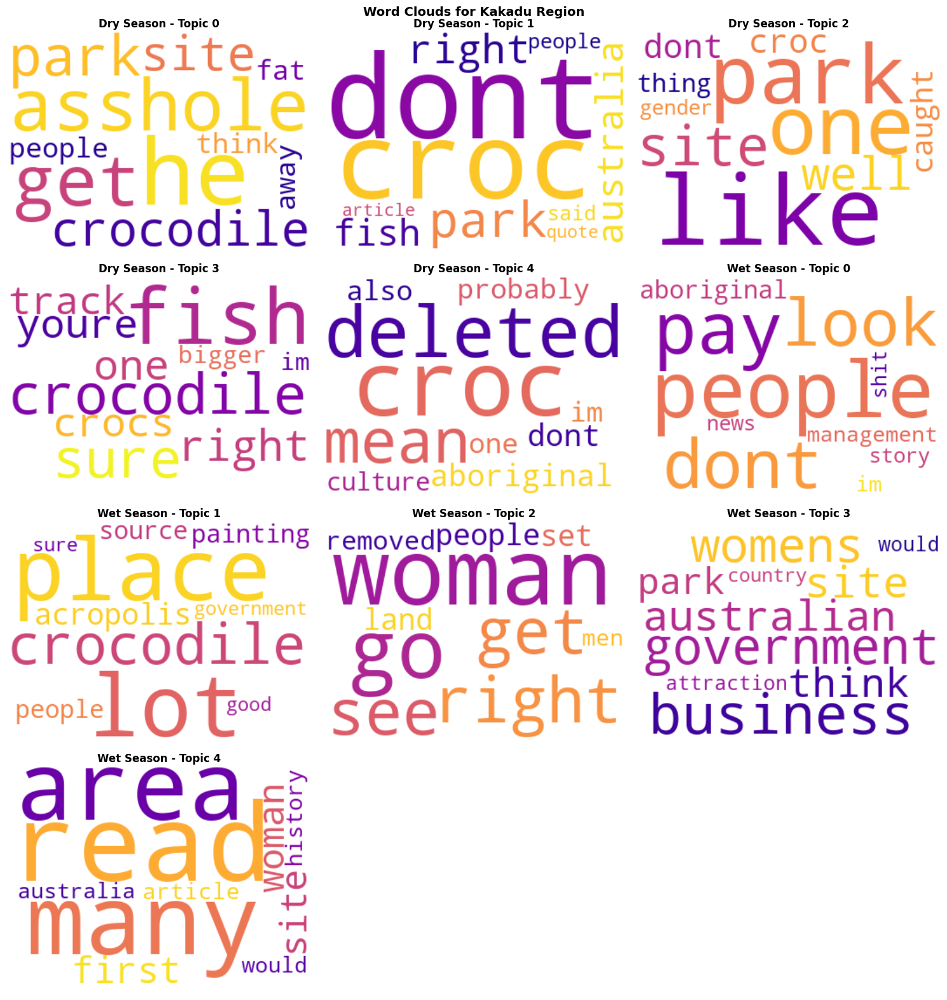

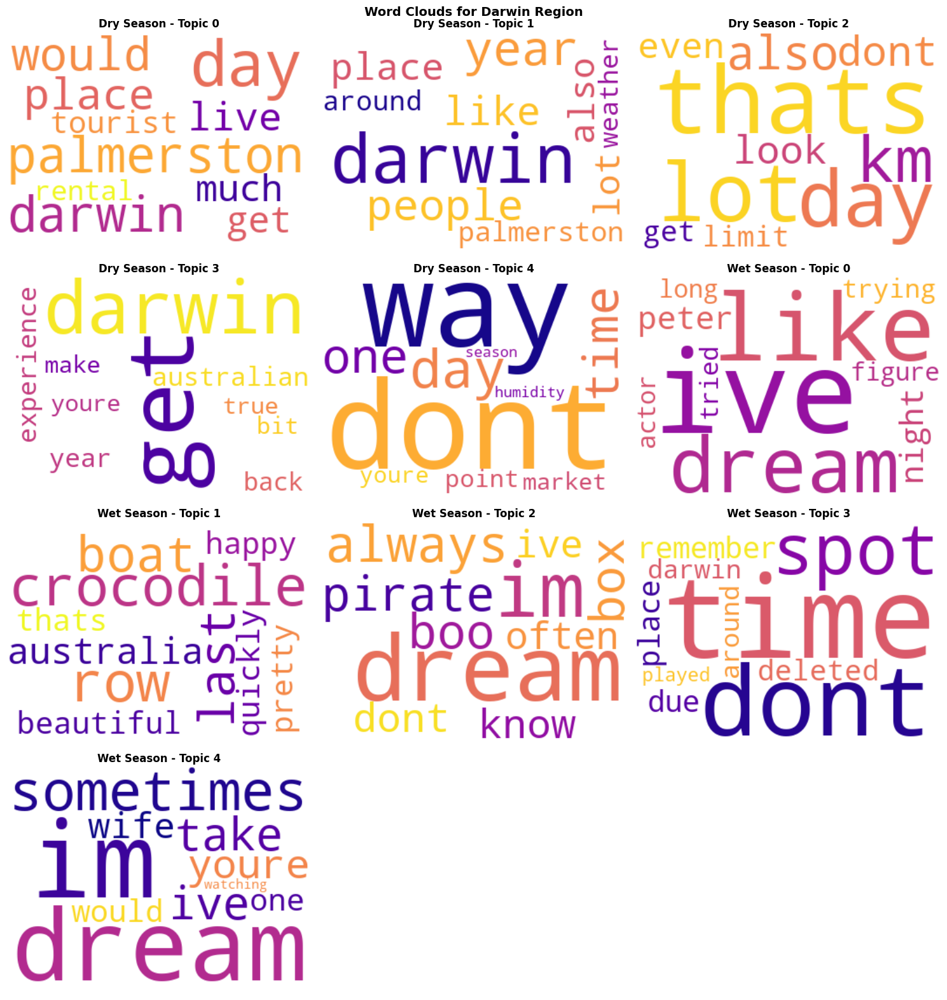

Topic modeling statistics exported to Output/reddit_topic_modelling.txt


In [6]:
# Assuming df is already loaded and preprocessed with 'Processed Comment', 'date', 'region' columns

# Add Season column to df
df['Month'] = df['date'].dt.month
df['Season'] = df['Month'].map({
    5: 'Dry', 6: 'Dry', 7: 'Dry', 8: 'Dry', 9: 'Dry', 10: 'Dry',  # May to October
    11: 'Wet', 12: 'Wet', 1: 'Wet', 2: 'Wet', 3: 'Wet', 4: 'Wet'   # November to April
})

# Part 2: Topic Modeling using LDA (Gensim) - Grouped by Season and Region

# For global topics (optional, for reference)
filtered_df = df[df['Processed Comment'].str.strip().astype(bool)].copy()
texts = [text.split() for text in filtered_df['Processed Comment']]
dictionary = corpora.Dictionary(texts)
corpus = [dictionary.doc2bow(text) for text in texts]
lda_model = LdaModel(corpus, num_topics=5, id2word=dictionary, passes=15)

print("Global Top Topics:")
for idx, topic in lda_model.print_topics(5):
    print(f"Topic {idx}: {topic}")

# Assign global dominant topics
def get_dominant_topic(bow):
    topics = lda_model.get_document_topics(bow)
    return max(topics, key=lambda x: x[1])[0] if topics else -1

filtered_df['Dominant Topic'] = [get_dominant_topic(bow) for bow in corpus]

# Drop 'Dominant Topic' from df if it exists to avoid duplicate columns
if 'Dominant Topic' in df.columns:
    df = df.drop(columns=['Dominant Topic'])

df = df.merge(filtered_df[['Dominant Topic']], left_index=True, right_index=True, how='left')
df['Dominant Topic'] = df['Dominant Topic'].fillna(-1)

# Visualize Topic Distribution by Season and Region
g = sns.catplot(
    data=df, 
    x='Dominant Topic', 
    col='region', 
    row='Season', 
    kind='count', 
    height=4, 
    aspect=1.5, 
    palette='viridis'
)
g.set_titles("{row_name} Season - {col_name} Region")
g.set_axis_labels("Dominant Topic", "Count")
g.fig.suptitle('Topic Distribution by Season and Region', fontsize=16, y=1.02)
plt.show()

# Heatmap of topic counts by region and season
pivot_table = df.pivot_table(
    index=['region', 'Season'], 
    columns='Dominant Topic', 
    aggfunc='size', 
    fill_value=0
)
plt.figure(figsize=(12, 8))
sns.heatmap(pivot_table, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Heatmap of Topic Counts by Region and Season')
plt.ylabel('Region - Season')
plt.xlabel('Dominant Topic')
plt.tight_layout()
plt.show()

# ...existing code...

# Separate LDA Models per Region-Season Group
min_comments = 20
word_cloud_data = []  # Store word cloud data for grid display

for region in df['region'].unique():
    for season in ['Dry', 'Wet']:
        sub_df = df[(df['region'] == region) & (df['Season'] == season)]
        sub_filtered = sub_df[sub_df['Processed Comment'].str.strip().astype(bool)]
        
        if len(sub_filtered) < min_comments:
            print(f"Skipping {region} - {season}: Only {len(sub_filtered)} comments (less than {min_comments})")
            continue
        
        print(f"\nProcessing {region} - {season} ({len(sub_filtered)} comments)")
        
        sub_texts = [text.split() for text in sub_filtered['Processed Comment']]
        sub_dictionary = corpora.Dictionary(sub_texts)
        sub_corpus = [sub_dictionary.doc2bow(text) for text in sub_texts]
        
        num_topics = min(5, len(sub_filtered) // 10)
        sub_lda = LdaModel(sub_corpus, num_topics=num_topics, id2word=sub_dictionary, passes=15)
        
        print(f"Top Topics for {region} - {season}:")
        for idx, topic in sub_lda.print_topics(num_topics):
            print(f"Topic {idx}: {topic}")
        
        # Store word cloud data instead of displaying immediately
        for topic_id in range(sub_lda.num_topics):
            terms = sub_lda.show_topic(topic_id, 10)
            word_cloud_data.append({
                'region': region,
                'season': season,
                'topic_id': topic_id,
                'terms': dict(terms),
                'title': f'Topic {topic_id} - {region} ({season})'
            })

regions_with_data = list(set([wc['region'] for wc in word_cloud_data]))

for region in regions_with_data:
    region_data = [wc for wc in word_cloud_data if wc['region'] == region]
    
    if region_data:
        n_plots = len(region_data)
        n_cols = 3  # 3 columns per region
        n_rows = (n_plots + n_cols - 1) // n_cols
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
        if n_plots == 1:
            axes = [axes]
        else:
            axes = axes.flatten()
        
        for i, wc_data in enumerate(region_data):
            wordcloud = WordCloud(
                width=350,
                height=250,
                background_color='white',
                max_words=40,
                colormap='plasma'
            ).generate_from_frequencies(wc_data['terms'])
            
            ax = axes[i]
            ax.imshow(wordcloud, interpolation='bilinear')
            ax.set_title(f"{wc_data['season']} Season - Topic {wc_data['topic_id']}", 
                        fontsize=12, fontweight='bold')
            ax.axis('off')
        
        # Hide empty subplots
        for j in range(i + 1, len(axes)):
            axes[j].axis('off')
        
        plt.suptitle(f'Word Clouds for {region} Region', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()



# Create Output directory if it doesn't exist
os.makedirs('Output', exist_ok=True)

# Export statistics to file
output_file = 'Output/reddit_topic_modelling.txt'
with open(output_file, 'w', encoding='utf-8') as f:
    f.write("Reddit Topic Modeling Statistics\n")
    f.write("=" * 50 + "\n\n")
    
    f.write("Global Top Topics:\n")
    for idx, topic in lda_model.print_topics(5):
        terms = topic.split(' + ')
        topic_terms = ', '.join([t.split('*')[1].strip('"') for t in terms])
        f.write(f"Topic {idx}: {topic_terms}\n")
    f.write("\n")
    
    f.write("Global Topic Distribution:\n")
    topic_counts = df['Dominant Topic'].value_counts(normalize=True) * 100
    for topic, percentage in topic_counts.items():
        f.write(f"Topic {topic}: {percentage:.2f}%\n")
    f.write("\n")
    
    f.write("Topic Distribution by Region and Season:\n")
    pivot_table = df.pivot_table(
        index=['region', 'Season'], 
        columns='Dominant Topic', 
        aggfunc='size', 
        fill_value=0
    )
    f.write(pivot_table.to_string() + "\n\n")
    
    f.write("Region-Season Specific Topic Modeling:\n")
    min_comments = 20
    for region in sorted(df['region'].unique()):
        for season in ['Dry', 'Wet']:
            sub_df = df[(df['region'] == region) & (df['Season'] == season)]
            sub_filtered = sub_df[sub_df['Processed Comment'].str.strip().astype(bool)]
            
            if len(sub_filtered) < min_comments:
                f.write(f"\n{region} - {season}: Only {len(sub_filtered)} comments (less than {min_comments})\n")
                continue
            
            f.write(f"\n{region} - {season} ({len(sub_filtered)} comments):\n")
            sub_texts = [text.split() for text in sub_filtered['Processed Comment']]
            sub_dictionary = corpora.Dictionary(sub_texts)
            sub_corpus = [sub_dictionary.doc2bow(text) for text in sub_texts]
            num_topics = min(5, len(sub_filtered) // 10)
            sub_lda = LdaModel(sub_corpus, num_topics=num_topics, id2word=sub_dictionary, passes=15)
            
            f.write(f"Top Topics for {region} - {season}:\n")
            for idx, topic in sub_lda.print_topics(num_topics):
                terms = topic.split(' + ')
                topic_terms = ', '.join([t.split('*')[1].strip('"') for t in terms])
                f.write(f"  Topic {idx}: {topic_terms}\n")
            f.write("\n")

print(f"Topic modeling statistics exported to {output_file}")


PART 3: CLUSTERING REDDIT COMMENTS USING K-MEANS ON TF-IDF


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


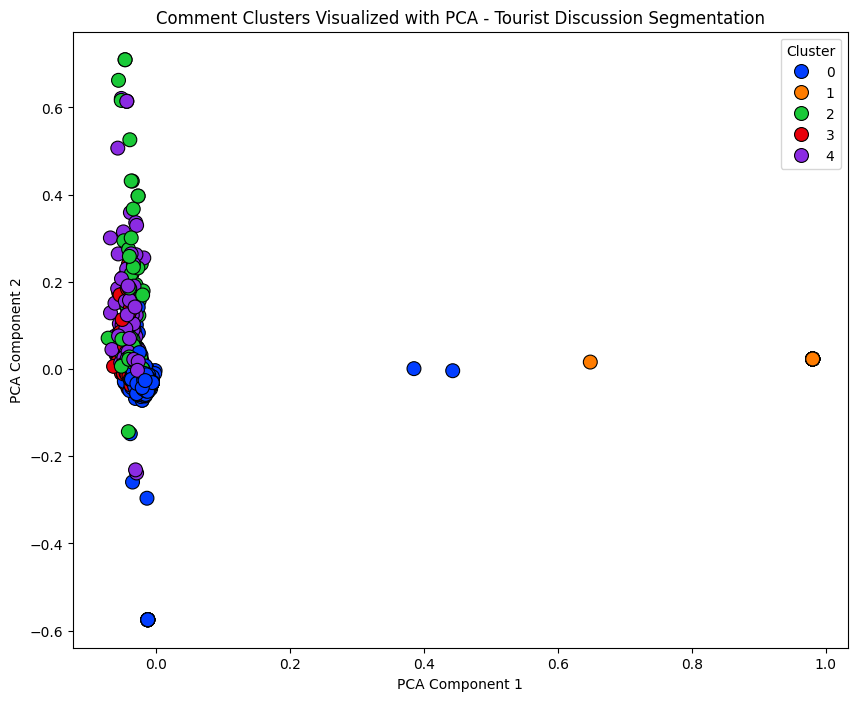


Overall Cluster Analysis:
Cluster 0 Top Terms (Discussion Theme): crocodile, thank, croc, spider, one, im, well, thats, thanks, removed
Cluster 1 Top Terms (Discussion Theme): fine, find, field, feel, far, family, found, yulara, post, deleted
Cluster 2 Top Terms (Discussion Theme): spring, time, also, national, fly, like, alice, park, look, get
Cluster 3 Top Terms (Discussion Theme): hour, time, around, ago, one, australia, place, year, day, darwin
Cluster 4 Top Terms (Discussion Theme): im, also, want, think, know, one, people, would, like, dont

CLUSTERING ANALYSIS GROUPED BY SEASON

Season: Dry


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Cluster 0 Top Terms: make, area, away, police, right, like, season, youre, dont, get
Cluster 1 Top Terms: one, make, back, time, hour, year, around, place, day, darwin
Cluster 2 Top Terms: one, crocs, fish, thats, park, well, australia, kookaburra, thanks, croc
Cluster 3 Top Terms: sure, know, also, think, look, people, one, like, im, dont
Cluster 4 Top Terms: given, getting, get, fuck, friday, food, give, care, post, deleted

Season: Wet


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Cluster 0 Top Terms: fruit, friend, found, fly, flight, first, fire, get, yulara, deleted
Cluster 1 Top Terms: seen, would, think, beautiful, thing, place, ive, australia, one, like
Cluster 2 Top Terms: trip, day, time, yulara, spring, rock, uluru, say, fly, alice
Cluster 3 Top Terms: still, people, probably, road, thanks, would, removed, thats, get, spider
Cluster 4 Top Terms: aboriginal, time, sometimes, dont, people, like, dream, see, im, look


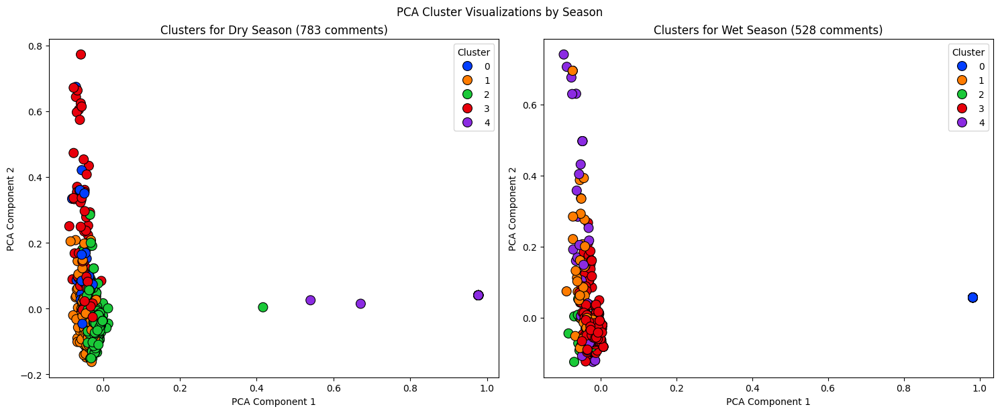


CLUSTERING ANALYSIS GROUPED BY REGION

Region: Kakadu
Cluster 0 Top Terms: right, get, crocs, removed, probably, think, dont, there, bad, say
Cluster 1 Top Terms: article, people, business, woman, shit, look, site, park, australia, like
Cluster 2 Top Terms: gender, fucking, fuck, found, fishing, fish, first, general, youre, deleted
Cluster 3 Top Terms: dont, faster, thats, great, hook, line, mean, caught, fish, croc
Cluster 4 Top Terms: right, also, thats, people, dont, know, sure, though, nile, crocodile

Region: Darwin


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Cluster 0 Top Terms: ive, youre, australia, year, much, last, palmerston, would, deleted, like
Cluster 1 Top Terms: northern, city, place, around, season, flight, year, hour, get, darwin
Cluster 2 Top Terms: think, miss, there, rest, darwin, mate, go, people, also, dont
Cluster 3 Top Terms: always, australian, anything, territory, ive, nothing, wife, sometimes, im, dream
Cluster 4 Top Terms: club, one, car, market, km, awesome, lot, gt, thanks, day

Region: Northern Territory
Cluster 0 Top Terms: big, week, happened, day, see, rain, tourist, many, deleted, pissing
Cluster 1 Top Terms: really, month, remote, place, local, would, working, year, backpacker, work
Cluster 2 Top Terms: bar, right, club, bay, park, darwin, friendly, thats, cafe, dog
Cluster 3 Top Terms: one, rain, time, job, dont, people, cant, nt, get, police
Cluster 4 Top Terms: cost, airport, also, cheaper, drive, spring, bali, flight, fly, alice

Region: Katherine nt
Cluster 0 Top Terms: put, awesome, doesnt, ive, kiwi, p

/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Cluster 0 Top Terms: worker, water, park, swim, season, little, thank, fall, wet, military
Cluster 1 Top Terms: house, get, think, well, like, good, container, would, dont, one
Cluster 2 Top Terms: ground, grey, great, got, leave, lens, post, public, fine, deleted
Cluster 3 Top Terms: sealed, little, area, etc, wangi, camping, problem, top, crocodile, yes
Cluster 4 Top Terms: hand, guess, guard, ground, grey, great, got, going, youre, removed

Region: Uluru
Cluster 0 Top Terms: get, dont, enforced, know, thing, one, people, im, thats, climbing
Cluster 1 Top Terms: thought, spring, alice, airport, fly, climb, good, point, ayers, rock
Cluster 2 Top Terms: park, car, probably, alice, resort, youre, direct, airport, fly, uluru
Cluster 3 Top Terms: fuck, free, forget, food, following, flying, future, tip, post, deleted
Cluster 4 Top Terms: yulara, town, tour, time, dont, spring, trip, day, go, alice


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


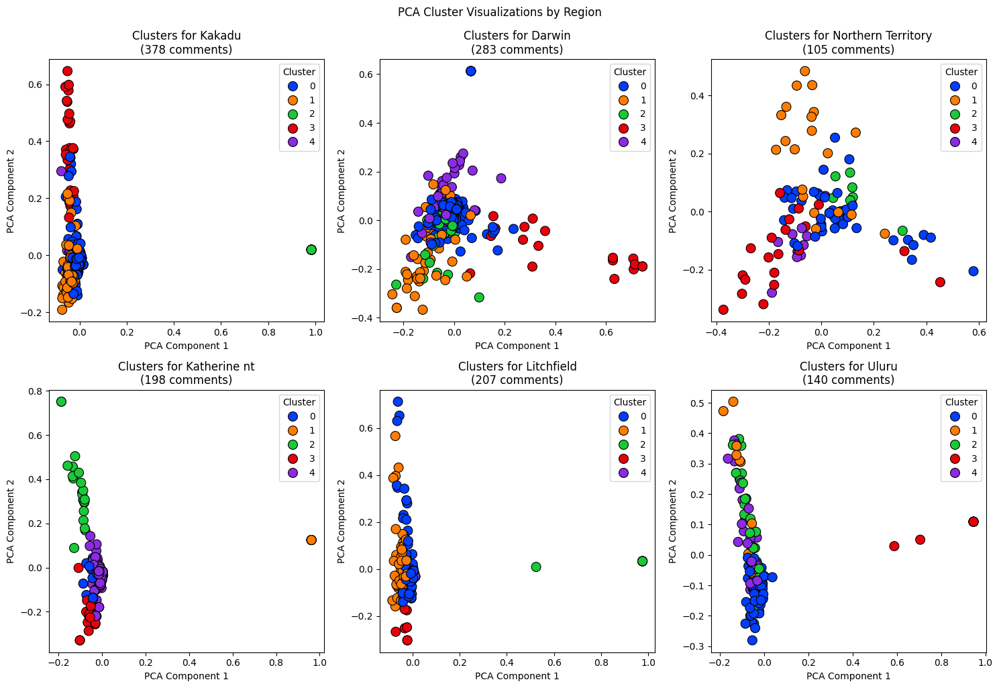


CLUSTERING ANALYSIS GROUPED BY REGION AND SEASON
Valid Region-Season combinations: 12
  Kakadu - Dry: 238 comments
  Kakadu - Wet: 140 comments
  Darwin - Dry: 207 comments
  Darwin - Wet: 76 comments
  Northern Territory - Dry: 82 comments
  Northern Territory - Wet: 23 comments
  Katherine nt - Dry: 70 comments
  Katherine nt - Wet: 128 comments
  Litchfield - Dry: 89 comments
  Litchfield - Wet: 118 comments
  Uluru - Dry: 97 comments
  Uluru - Wet: 43 comments

Region-Season: Kakadu - Dry
Cluster 0 Top Terms: forced, forcing, fuck, gender, general, get, fat, deleted
Cluster 1 Top Terms: also, salties, dont, though, nile, people, crocs, crocodile
Cluster 2 Top Terms: bigger, got, day, back, always, croc, caught, fish
Cluster 3 Top Terms: maxi, right, like, one, get, park, dont, croc

Region-Season: Kakadu - Wet


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Cluster 0 Top Terms: place, like, australian, source, removed, well, look, people
Cluster 1 Top Terms: cant, culture, site, sexism, men, womens, business, woman
Cluster 2 Top Terms: easy, history, go, year, australia, human, say, read
Cluster 3 Top Terms: isnt, enough, nose, good, around, article, lot, there

Region-Season: Darwin - Dry
Cluster 0 Top Terms: probably, people, good, also, many, territorian, youre, dont
Cluster 1 Top Terms: friday, wharf, go, darwin, place, visit, spring, palmerston
Cluster 2 Top Terms: wet, around, dry, humidity, year, season, hour, darwin
Cluster 3 Top Terms: like, much, im, thank, lot, get, day, thanks

Region-Season: Darwin - Wet
Cluster 0 Top Terms: due, dream, go, ive, last, night, trying, escape
Cluster 1 Top Terms: peter, actor, asked, cameo, stuff, story, maybe, like
Cluster 2 Top Terms: peter, deleted, australia, crocodile, time, dont, ive, last
Cluster 3 Top Terms: youre, watching, ive, anyone, sometimes, wife, im, dream

Region-Season: Norther

/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_

Cluster 0 Top Terms: one, time, people, thing, year, place, many, police
Cluster 1 Top Terms: club, would, work, well, build, two, dog, pissing
Cluster 2 Top Terms: there, need, see, around, spring, go, tourist, alice
Cluster 3 Top Terms: said, season, didnt, tease, come, pissing, bit, rain

Region-Season: Northern Territory - Wet
Cluster 0 Top Terms: also, there, alice, month, people, working, local, work
Cluster 1 Top Terms: international, jabiru, job, like, europe, youre, bali, see
Cluster 2 Top Terms: two, domestic, time, fly, trip, perth, europe, cost
Cluster 3 Top Terms: two, jabiru, really, young, australia, one, working, backpacker

Region-Season: Katherine nt - Dry
Cluster 0 Top Terms: heard, house, im, ive, kookaburra, bird, love, laugh
Cluster 1 Top Terms: look, deleted, one, bluewinged, like, beautiful, blue, kookaburra
Cluster 2 Top Terms: person, see, near, saw, majestic, thanks, blue, one
Cluster 3 Top Terms: katherine, demonic, arent, kookaburra, sits, gum, old, tree

R

/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Cluster 0 Top Terms: kiwi, darwin, removed, like, get, dauber, wasp, australia
Cluster 1 Top Terms: break, love, still, open, paralyzed, thats, jumping, spider
Cluster 2 Top Terms: 53, little, looking, guy, day, truck, give, one
Cluster 3 Top Terms: guy, hanging, hell, hey, hot, good, youre, deleted

Region-Season: Litchfield - Dry
Cluster 0 Top Terms: ive, grey, water, fall, end, area, way, swam
Cluster 1 Top Terms: water, like, summer, park, well, dont, australia, one
Cluster 2 Top Terms: hey, hot, im, ive, jungle, miss, youre, removed
Cluster 3 Top Terms: hot, im, ive, jungle, kakadu, public, post, deleted

Region-Season: Litchfield - Wet
Cluster 0 Top Terms: yes, little, wet, get, thank, deleted, worker, want
Cluster 1 Top Terms: would, build, rust, quite, cut, inside, house, container
Cluster 2 Top Terms: people, thanking, go, etc, also, working, worship, military
Cluster 3 Top Terms: also, one, national, see, im, like, thats, would

Region-Season: Uluru - Dry


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Cluster 0 Top Terms: uluru, climb, king, bit, national, one, park, day
Cluster 1 Top Terms: sound, well, campground, know, thank, thought, thanks, good
Cluster 2 Top Terms: time, im, uluru, rock, fine, get, people, climbing
Cluster 3 Top Terms: fence, field, easy, youre, tip, tell, post, deleted

Region-Season: Uluru - Wet
Cluster 0 Top Terms: long, ayq, fly, ayers, spring, alice, airport, rock
Cluster 1 Top Terms: field, fine, flight, fly, experience, yulara, much, thats
Cluster 2 Top Terms: night, yulara, lol, day, looking, trip, town, go
Cluster 3 Top Terms: also, dont, coming, stay, direct, drove, fly, uluru


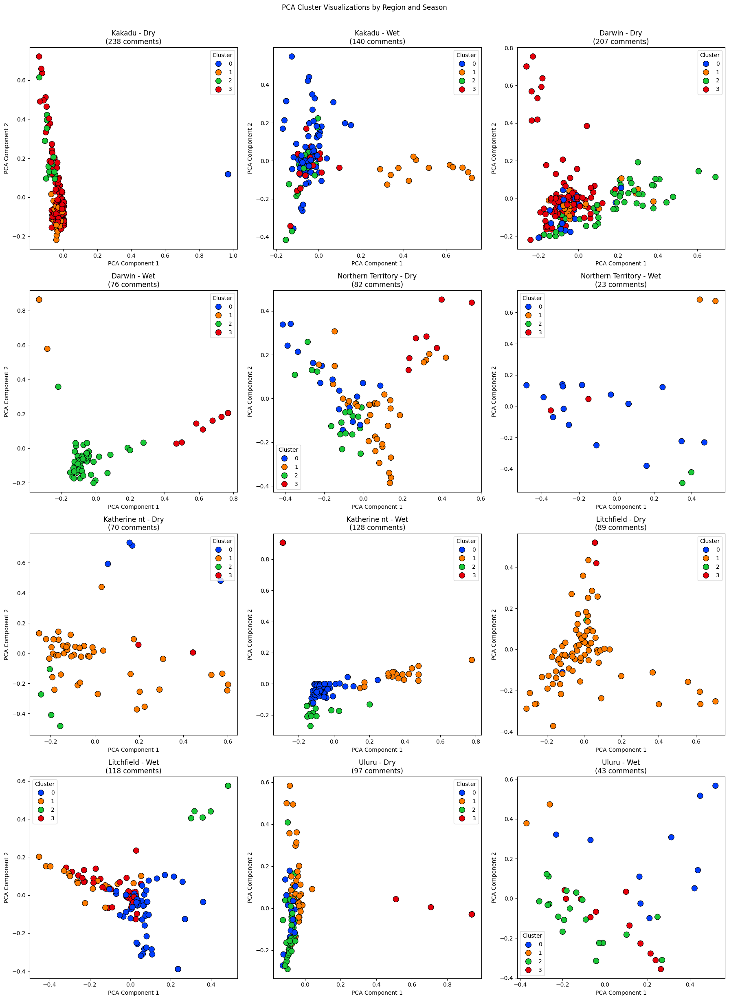


CLUSTER QUALITY ANALYSIS

Overall Clustering Quality:
Silhouette Score: 0.045 (Range: [-1, 1], Higher is better)
Calinski-Harabasz Score: 15.250 (Higher is better)
Davies-Bouldin Score: 6.769 (Lower is better)

BUSINESS INSIGHTS SUMMARY

CLUSTER SUMMARY TABLE:
 Cluster ID  Size  Avg Sentiment Score Dominant Season Dominant Region          Top Regions  Avg Reddit Score  Positive %  Negative %  Neutral %          Top Discussion Topics
          0   751                0.107             Dry          Kakadu Kakadu, Katherine nt              32.3        40.1        20.0       39.9      im, one, thats, well, ive
          1    33                0.021             Dry          Kakadu        Kakadu, Uluru              17.5         3.0         0.0       97.0 deleted, combative, depende...
          2   160                0.110             Dry           Uluru        Uluru, Kakadu              23.6        47.5        30.6       21.9    get, park, look, alice, fly
          3   179                0

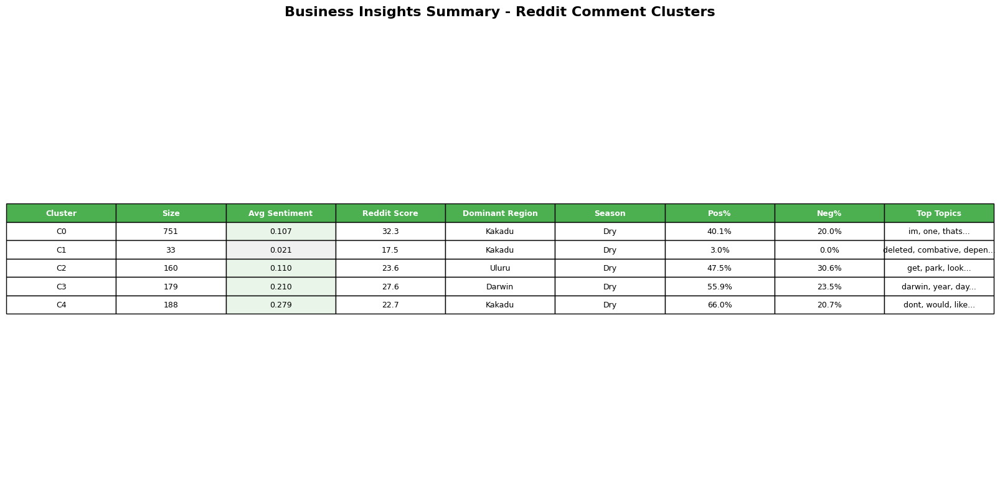


Business insights summary exported to 'cluster_business_insights.csv'


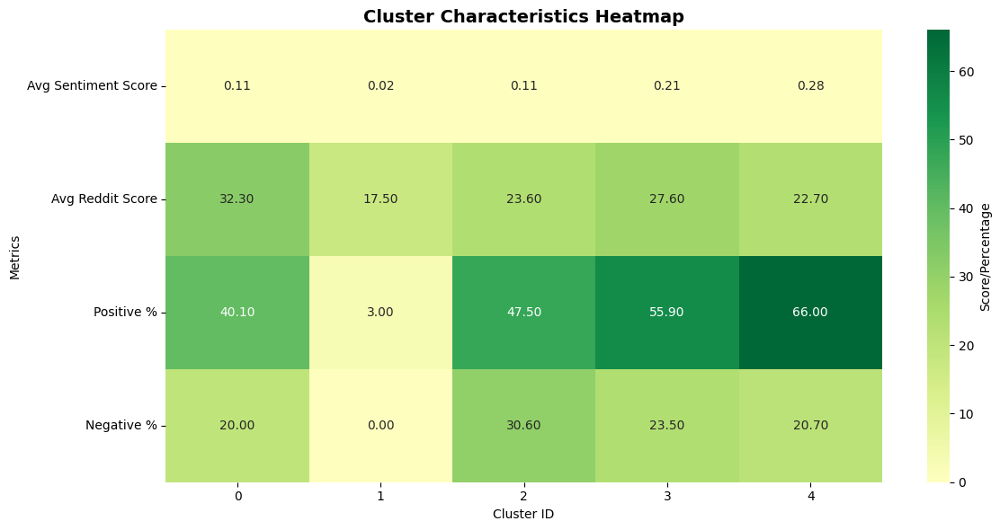


CLUSTERING ANALYSIS COMPLETE


/opt/anaconda3/envs/Analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Clustering statistics exported to Output/reddit_clustering.txt


In [7]:
# Part 3: Enhanced Clustering Comments with PCA by Season and Region for Customer Segmentation
print("\n" + "="*80)
print("PART 3: CLUSTERING REDDIT COMMENTS USING K-MEANS ON TF-IDF")
print("="*80)

# Overall clustering first
vectorizer = TfidfVectorizer(max_features=500)
X = vectorizer.fit_transform(df['Processed Comment'])

kmeans = KMeans(n_clusters=5, random_state=42)
df['Cluster'] = kmeans.fit_predict(X)

# Visualize Clusters with PCA - Segments tourists for targeted marketing
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

# Add PCA components to dataframe
df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]

plt.figure(figsize=(10, 8))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['Cluster'], palette='bright', s=100, edgecolor='k')
plt.title('Comment Clusters Visualized with PCA - Tourist Discussion Segmentation')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster', loc='best')
plt.show()

# Prove Clusters: Top terms per cluster to label
feature_names = vectorizer.get_feature_names_out()
print("\nOverall Cluster Analysis:")
for i in range(5):
    center = kmeans.cluster_centers_[i]
    top_terms = [feature_names[idx] for idx in center.argsort()[-10:]]
    print(f"Cluster {i} Top Terms (Discussion Theme): {', '.join(top_terms)}")

# Group by Season for clustering
print("\n" + "="*60)
print("CLUSTERING ANALYSIS GROUPED BY SEASON")
print("="*60)

unique_seasons = ['Dry', 'Wet']
num_seasons = len(unique_seasons)
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

for idx, season in enumerate(unique_seasons):
    print(f"\nSeason: {season}")
    season_df = df[df['Season'] == season]
    if len(season_df) < 10:
        print("Insufficient data for clustering.")
        axs[idx].text(0.5, 0.5, f'Insufficient data\n({len(season_df)} comments)', 
                      ha='center', va='center', transform=axs[idx].transAxes, fontsize=12)
        axs[idx].set_title(f'Clusters for {season} Season')
        continue
    
    # Create season-specific vectorizer
    season_vectorizer = TfidfVectorizer(max_features=300)
    season_X = season_vectorizer.fit_transform(season_df['Processed Comment'])
    
    if season_X.shape[0] < 5:  # Need at least 5 samples for 5 clusters
        print("Insufficient data for 5 clusters.")
        continue
    
    season_kmeans = KMeans(n_clusters=5, random_state=42)
    season_clusters = season_kmeans.fit_predict(season_X)
    
    season_pca = PCA(n_components=2)
    season_X_pca = season_pca.fit_transform(season_X.toarray())
    
    # Create temporary dataframe for plotting
    plot_df = pd.DataFrame({
        'PCA1': season_X_pca[:, 0],
        'PCA2': season_X_pca[:, 1],
        'Season_Cluster': season_clusters
    })
    
    sns.scatterplot(data=plot_df, x='PCA1', y='PCA2', hue='Season_Cluster', 
                   palette='bright', s=100, edgecolor='k', ax=axs[idx])
    axs[idx].set_title(f'Clusters for {season} Season ({len(season_df)} comments)')
    axs[idx].set_xlabel('PCA Component 1')
    axs[idx].set_ylabel('PCA Component 2')
    axs[idx].legend(title='Cluster', loc='best')
    
    # Top terms for each cluster in this season
    season_feature_names = season_vectorizer.get_feature_names_out()
    for i in range(5):
        center = season_kmeans.cluster_centers_[i]
        top_terms = [season_feature_names[idx] for idx in center.argsort()[-10:]]
        print(f"Cluster {i} Top Terms: {', '.join(top_terms)}")

plt.tight_layout()
plt.suptitle('PCA Cluster Visualizations by Season', y=1.02)
plt.show()

# Group by Region for clustering
print("\n" + "="*60)
print("CLUSTERING ANALYSIS GROUPED BY REGION")
print("="*60)

unique_regions = df['region'].unique()
num_regions = len(unique_regions)
rows = (num_regions + 2) // 3  # For 3 columns grid
fig, axs = plt.subplots(rows, 3, figsize=(15, 5 * rows))
axs = axs.flatten()

for idx, region in enumerate(unique_regions):
    print(f"\nRegion: {region}")
    region_df = df[df['region'] == region]
    if len(region_df) < 10:
        print("Insufficient data for clustering.")
        axs[idx].text(0.5, 0.5, f'Insufficient data\n({len(region_df)} comments)', 
                      ha='center', va='center', transform=axs[idx].transAxes, fontsize=10)
        axs[idx].set_title(f'Clusters for {region}')
        continue
    
    # Create region-specific vectorizer
    region_vectorizer = TfidfVectorizer(max_features=300)
    region_X = region_vectorizer.fit_transform(region_df['Processed Comment'])
    
    if region_X.shape[0] < 5:  # Need at least 5 samples for 5 clusters
        print("Insufficient data for 5 clusters.")
        continue
    
    region_kmeans = KMeans(n_clusters=5, random_state=42)
    region_clusters = region_kmeans.fit_predict(region_X)
    
    region_pca = PCA(n_components=2)
    region_X_pca = region_pca.fit_transform(region_X.toarray())
    
    # Create temporary dataframe for plotting
    plot_df = pd.DataFrame({
        'PCA1': region_X_pca[:, 0],
        'PCA2': region_X_pca[:, 1],
        'Region_Cluster': region_clusters
    })
    
    sns.scatterplot(data=plot_df, x='PCA1', y='PCA2', hue='Region_Cluster', 
                   palette='bright', s=100, edgecolor='k', ax=axs[idx])
    axs[idx].set_title(f'Clusters for {region}\n({len(region_df)} comments)')
    axs[idx].set_xlabel('PCA Component 1')
    axs[idx].set_ylabel('PCA Component 2')
    axs[idx].legend(title='Cluster', loc='best')
    
    # Top terms for each cluster in this region
    region_feature_names = region_vectorizer.get_feature_names_out()
    for i in range(5):
        center = region_kmeans.cluster_centers_[i]
        top_terms = [region_feature_names[idx] for idx in center.argsort()[-10:]]
        print(f"Cluster {i} Top Terms: {', '.join(top_terms)}")

# Hide unused subplots
for j in range(idx + 1, len(axs)):
    axs[j].axis('off')

plt.tight_layout()
plt.suptitle('PCA Cluster Visualizations by Region', y=1.02)
plt.show()

# Group by Region-Season Combination for clustering
print("\n" + "="*60)
print("CLUSTERING ANALYSIS GROUPED BY REGION AND SEASON")
print("="*60)

# Create combinations that have sufficient data
valid_combinations = []
for region in unique_regions:
    for season in unique_seasons:
        subset_df = df[(df['region'] == region) & (df['Season'] == season)]
        if len(subset_df) >= 15:  # Minimum threshold for meaningful clustering
            valid_combinations.append((region, season, len(subset_df)))

print(f"Valid Region-Season combinations: {len(valid_combinations)}")
for region, season, count in valid_combinations:
    print(f"  {region} - {season}: {count} comments")

if valid_combinations:
    num_combinations = len(valid_combinations)
    rows = (num_combinations + 2) // 3  # For 3 columns grid
    fig, axs = plt.subplots(rows, 3, figsize=(18, 6 * rows))
    if num_combinations == 1:
        axs = [axs]
    else:
        axs = axs.flatten()

    for idx, (region, season, count) in enumerate(valid_combinations):
        print(f"\nRegion-Season: {region} - {season}")
        subset_df = df[(df['region'] == region) & (df['Season'] == season)]
        
        # Create subset-specific vectorizer
        subset_vectorizer = TfidfVectorizer(max_features=200, min_df=2)
        subset_X = subset_vectorizer.fit_transform(subset_df['Processed Comment'])
        
        n_clusters = min(4, subset_X.shape[0]//3)  # Adaptive number of clusters
        subset_kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        subset_clusters = subset_kmeans.fit_predict(subset_X)
        
        subset_pca = PCA(n_components=2)
        subset_X_pca = subset_pca.fit_transform(subset_X.toarray())
        
        # Create temporary dataframe for plotting
        plot_df = pd.DataFrame({
            'PCA1': subset_X_pca[:, 0],
            'PCA2': subset_X_pca[:, 1],
            'Subset_Cluster': subset_clusters
        })
        
        sns.scatterplot(data=plot_df, x='PCA1', y='PCA2', hue='Subset_Cluster', 
                       palette='bright', s=100, edgecolor='k', ax=axs[idx])
        axs[idx].set_title(f'{region} - {season}\n({count} comments)')
        axs[idx].set_xlabel('PCA Component 1')
        axs[idx].set_ylabel('PCA Component 2')
        axs[idx].legend(title='Cluster', loc='best')
        
        # Top terms for each cluster in this region-season combination
        subset_feature_names = subset_vectorizer.get_feature_names_out()
        for i in range(n_clusters):
            center = subset_kmeans.cluster_centers_[i]
            top_terms = [subset_feature_names[idx] for idx in center.argsort()[-8:]]
            print(f"Cluster {i} Top Terms: {', '.join(top_terms)}")

    # Hide unused subplots
    for j in range(len(valid_combinations), len(axs)):
        axs[j].axis('off')

    plt.tight_layout()
    plt.suptitle('PCA Cluster Visualizations by Region and Season', y=1.02)
    plt.show()

# Advanced Analysis: Cluster Quality Metrics
print("\n" + "="*60)
print("CLUSTER QUALITY ANALYSIS")
print("="*60)

from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Overall clustering quality
silhouette_avg = silhouette_score(X, df['Cluster'])
calinski_score = calinski_harabasz_score(X.toarray(), df['Cluster'])
davies_bouldin = davies_bouldin_score(X.toarray(), df['Cluster'])

print(f"\nOverall Clustering Quality:")
print(f"Silhouette Score: {silhouette_avg:.3f} (Range: [-1, 1], Higher is better)")
print(f"Calinski-Harabasz Score: {calinski_score:.3f} (Higher is better)")
print(f"Davies-Bouldin Score: {davies_bouldin:.3f} (Lower is better)")

# ...existing code...

# Business Insights Summary
print("\n" + "="*60)
print("BUSINESS INSIGHTS SUMMARY")
print("="*60)

# Create a comprehensive summary table
import pandas as pd

summary_data = []
for cluster_id in sorted(df['Cluster'].unique()):
    cluster_data = df[df['Cluster'] == cluster_id]
    
    # Calculate statistics
    avg_sentiment = cluster_data['Compound Score'].mean()
    dominant_season = cluster_data['Season'].mode().iloc[0] if len(cluster_data['Season'].mode()) > 0 else 'Mixed'
    dominant_region = cluster_data['region'].mode().iloc[0] if len(cluster_data['region'].mode()) > 0 else 'Mixed'
    avg_reddit_score = cluster_data['score'].mean()
    
    # Top discussion topics
    cluster_text = ' '.join(cluster_data['Processed Comment'])
    words = cluster_text.split()
    word_counts = Counter(words)
    top_words = [word for word, count in word_counts.most_common(5)]  # Top 5 for table readability
    
    # Sentiment distribution
    sentiment_dist = cluster_data['Sentiment'].value_counts(normalize=True) * 100
    positive_pct = sentiment_dist.get('Positive', 0)
    negative_pct = sentiment_dist.get('Negative', 0)
    neutral_pct = sentiment_dist.get('Neutral', 0)
    
    # Regional distribution
    region_dist = cluster_data['region'].value_counts()
    top_regions = list(region_dist.head(2).index)
    
    summary_data.append({
        'Cluster ID': cluster_id,
        'Size': len(cluster_data),
        'Avg Sentiment Score': round(avg_sentiment, 3),
        'Dominant Season': dominant_season,
        'Dominant Region': dominant_region,
        'Top Regions': ', '.join(top_regions),
        'Avg Reddit Score': round(avg_reddit_score, 1),
        'Positive %': round(positive_pct, 1),
        'Negative %': round(negative_pct, 1),
        'Neutral %': round(neutral_pct, 1),
        'Top Discussion Topics': ', '.join(top_words)
    })

# Create DataFrame and display as table
summary_df = pd.DataFrame(summary_data)

print("\nCLUSTER SUMMARY TABLE:")
print("="*120)
print(summary_df.to_string(index=False, max_colwidth=30))

# Create a more detailed breakdown table
print(f"\n{'='*120}")
print("DETAILED CLUSTER ANALYSIS TABLE")
print(f"{'='*120}")

# Detailed table with better formatting
detailed_data = []
for cluster_id in sorted(df['Cluster'].unique()):
    cluster_data = df[df['Cluster'] == cluster_id]
    
    # Regional breakdown
    region_breakdown = cluster_data['region'].value_counts()
    region_percentages = (region_breakdown / len(cluster_data) * 100).round(1)
    
    # Seasonal breakdown
    season_breakdown = cluster_data['Season'].value_counts()
    season_percentages = (season_breakdown / len(cluster_data) * 100).round(1)
    
    # Top terms with scores
    cluster_text = ' '.join(cluster_data['Processed Comment'])
    words = cluster_text.split()
    word_counts = Counter(words)
    top_terms_with_counts = word_counts.most_common(8)
    
    detailed_data.append({
        'Cluster': f"Cluster {cluster_id}",
        'Comments': len(cluster_data),
        'Sentiment Score': f"{cluster_data['Compound Score'].mean():.3f}",
        'Reddit Score': f"{cluster_data['score'].mean():.1f}",
        'Top Region': f"{region_breakdown.index[0] if len(region_breakdown) > 0 else 'N/A'} ({region_percentages.iloc[0] if len(region_percentages) > 0 else 0}%)",
        'Dominant Season': f"{season_breakdown.index[0] if len(season_breakdown) > 0 else 'N/A'} ({season_percentages.iloc[0] if len(season_percentages) > 0 else 0}%)",
        'Sentiment Distribution': f"Pos: {(cluster_data['Sentiment'] == 'Positive').mean()*100:.1f}% | Neg: {(cluster_data['Sentiment'] == 'Negative').mean()*100:.1f}% | Neu: {(cluster_data['Sentiment'] == 'Neutral').mean()*100:.1f}%",
        'Key Topics': ', '.join([f"{word}({count})" for word, count in top_terms_with_counts[:5]])
    })

detailed_df = pd.DataFrame(detailed_data)
print(detailed_df.to_string(index=False, max_colwidth=40))

# Create a visual summary table using matplotlib
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(16, 8))
ax.axis('tight')
ax.axis('off')

# Prepare data for the visual table
table_data = []
headers = ['Cluster', 'Size', 'Avg Sentiment', 'Reddit Score', 'Dominant Region', 'Season', 'Pos%', 'Neg%', 'Top Topics']

for cluster_id in sorted(df['Cluster'].unique()):
    cluster_data = df[df['Cluster'] == cluster_id]
    
    avg_sentiment = cluster_data['Compound Score'].mean()
    dominant_season = cluster_data['Season'].mode().iloc[0] if len(cluster_data['Season'].mode()) > 0 else 'Mixed'
    dominant_region = cluster_data['region'].mode().iloc[0] if len(cluster_data['region'].mode()) > 0 else 'Mixed'
    avg_reddit_score = cluster_data['score'].mean()
    
    # Sentiment percentages
    positive_pct = (cluster_data['Sentiment'] == 'Positive').mean() * 100
    negative_pct = (cluster_data['Sentiment'] == 'Negative').mean() * 100
    
    # Top topics (shortened for table)
    cluster_text = ' '.join(cluster_data['Processed Comment'])
    words = cluster_text.split()
    word_counts = Counter(words)
    top_words = [word for word, count in word_counts.most_common(3)]
    
    table_data.append([
        f"C{cluster_id}",
        len(cluster_data),
        f"{avg_sentiment:.3f}",
        f"{avg_reddit_score:.1f}",
        dominant_region[:12],  # Truncate for table fit
        dominant_season,
        f"{positive_pct:.1f}%",
        f"{negative_pct:.1f}%",
        ', '.join(top_words)[:25] + "..."  # Truncate long topics
    ])

# Create the table
table = ax.table(cellText=table_data, colLabels=headers, cellLoc='center', loc='center',
                colColours=['lightblue']*len(headers))
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.5)

# Style the table
for i in range(len(headers)):
    table[(0, i)].set_facecolor('#4CAF50')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Color code sentiment scores
for i, row in enumerate(table_data, 1):
    sentiment_score = float(row[2])
    if sentiment_score > 0.1:
        table[(i, 2)].set_facecolor('#E8F5E8')  # Light green for positive
    elif sentiment_score < -0.1:
        table[(i, 2)].set_facecolor('#FFE8E8')  # Light red for negative
    else:
        table[(i, 2)].set_facecolor('#F0F0F0')  # Light gray for neutral

plt.title('Business Insights Summary - Reddit Comment Clusters', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Export summary to CSV for further analysis
summary_df.to_csv('cluster_business_insights.csv', index=False)
print(f"\nBusiness insights summary exported to 'cluster_business_insights.csv'")

# Create a heatmap of cluster characteristics
cluster_metrics = summary_df[['Cluster ID', 'Avg Sentiment Score', 'Avg Reddit Score', 'Positive %', 'Negative %']].set_index('Cluster ID')

plt.figure(figsize=(12, 6))
sns.heatmap(cluster_metrics.T, annot=True, cmap='RdYlGn', center=0, 
            cbar_kws={'label': 'Score/Percentage'}, fmt='.2f')
plt.title('Cluster Characteristics Heatmap', fontsize=14, fontweight='bold')
plt.xlabel('Cluster ID')
plt.ylabel('Metrics')
plt.tight_layout()
plt.show()

print(f"\n{'='*60}")
print("CLUSTERING ANALYSIS COMPLETE")
print(f"{'='*60}")


# Create Output directory if it doesn't exist
os.makedirs('Output', exist_ok=True)

# Export statistics to file
output_file = 'Output/reddit_clustering.txt'
with open(output_file, 'w', encoding='utf-8') as f:
    f.write("Reddit Clustering Statistics\n")
    f.write("=" * 80 + "\n\n")
    
    f.write("PART 3: CLUSTERING REDDIT COMMENTS USING K-MEANS ON TF-IDF\n")
    f.write("=" * 80 + "\n\n")
    
    f.write("Overall Cluster Analysis:\n")
    cluster_counts = df['Cluster'].value_counts(normalize=True) * 100
    for cluster, percentage in cluster_counts.items():
        f.write(f"Cluster {cluster}: {percentage:.2f}%\n")
    f.write("\n")
    
    f.write("Top Terms per Cluster (Overall):\n")
    feature_names = vectorizer.get_feature_names_out()
    for i in range(5):
        center = kmeans.cluster_centers_[i]
        top_terms = [feature_names[idx] for idx in center.argsort()[-10:]]
        f.write(f"Cluster {i} Top Terms (Discussion Theme): {', '.join(top_terms)}\n")
    f.write("\n")
    
    f.write("=" * 60 + "\n")
    f.write("CLUSTERING ANALYSIS GROUPED BY SEASON\n")
    f.write("=" * 60 + "\n")
    
    unique_seasons = ['Dry', 'Wet']
    for season in unique_seasons:
        f.write(f"\nSeason: {season}\n")
        season_df = df[df['Season'] == season]
        if len(season_df) < 10:
            f.write(f"Insufficient data for clustering ({len(season_df)} comments).\n")
            continue
        
        season_vectorizer = TfidfVectorizer(max_features=300)
        season_X = season_vectorizer.fit_transform(season_df['Processed Comment'])
        if season_X.shape[0] < 5:
            f.write("Insufficient data for 5 clusters.\n")
            continue
        
        season_kmeans = KMeans(n_clusters=5, random_state=42)
        season_clusters = season_kmeans.fit_predict(season_X)
        
        f.write(f"Cluster Distribution for {season} ({len(season_df)} comments):\n")
        season_cluster_counts = pd.Series(season_clusters).value_counts(normalize=True) * 100
        for cluster, percentage in season_cluster_counts.items():
            f.write(f"Cluster {cluster}: {percentage:.2f}%\n")
        
        f.write(f"Top Terms per Cluster for {season}:\n")
        season_feature_names = season_vectorizer.get_feature_names_out()
        for i in range(5):
            center = season_kmeans.cluster_centers_[i]
            top_terms = [season_feature_names[idx] for idx in center.argsort()[-10:]]
            f.write(f"Cluster {i} Top Terms: {', '.join(top_terms)}\n")
        f.write("\n")
    
    f.write("=" * 60 + "\n")
    f.write("CLUSTERING ANALYSIS GROUPED BY REGION\n")
    f.write("=" * 60 + "\n")
    
    unique_regions = df['region'].unique()
    for region in sorted(unique_regions):
        f.write(f"\nRegion: {region}\n")
        region_df = df[df['region'] == region]
        if len(region_df) < 10:
            f.write(f"Insufficient data for clustering ({len(region_df)} comments).\n")
            continue
        
        region_vectorizer = TfidfVectorizer(max_features=300)
        region_X = region_vectorizer.fit_transform(region_df['Processed Comment'])
        if region_X.shape[0] < 5:
            f.write("Insufficient data for 5 clusters.\n")
            continue
        
        region_kmeans = KMeans(n_clusters=5, random_state=42)
        region_clusters = region_kmeans.fit_predict(region_X)
        
        f.write(f"Cluster Distribution for {region} ({len(region_df)} comments):\n")
        region_cluster_counts = pd.Series(region_clusters).value_counts(normalize=True) * 100
        for cluster, percentage in region_cluster_counts.items():
            f.write(f"Cluster {cluster}: {percentage:.2f}%\n")
        
        f.write(f"Top Terms per Cluster for {region}:\n")
        region_feature_names = region_vectorizer.get_feature_names_out()
        for i in range(5):
            center = region_kmeans.cluster_centers_[i]
            top_terms = [region_feature_names[idx] for idx in center.argsort()[-10:]]
            f.write(f"Cluster {i} Top Terms: {', '.join(top_terms)}\n")
        f.write("\n")
    
    f.write("=" * 60 + "\n")
    f.write("CLUSTERING ANALYSIS GROUPED BY REGION AND SEASON\n")
    f.write("=" * 60 + "\n")
    
    valid_combinations = [(region, season, len(df[(df['region'] == region) & (df['Season'] == season)])) 
                         for region in unique_regions for season in unique_seasons 
                         if len(df[(df['region'] == region) & (df['Season'] == season)]) >= 15]
    
    f.write(f"Valid Region-Season Combinations: {len(valid_combinations)}\n")
    for region, season, count in valid_combinations:
        f.write(f"  {region} - {season}: {count} comments\n")
    
    for region, season, count in valid_combinations:
        f.write(f"\nRegion-Season: {region} - {season}\n")
        subset_df = df[(df['region'] == region) & (df['Season'] == season)]
        
        subset_vectorizer = TfidfVectorizer(max_features=200, min_df=2)
        subset_X = subset_vectorizer.fit_transform(subset_df['Processed Comment'])
        n_clusters = min(4, subset_X.shape[0]//3)
        subset_kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        subset_clusters = subset_kmeans.fit_predict(subset_X)
        
        f.write(f"Cluster Distribution for {region} - {season} ({count} comments):\n")
        subset_cluster_counts = pd.Series(subset_clusters).value_counts(normalize=True) * 100
        for cluster, percentage in subset_cluster_counts.items():
            f.write(f"Cluster {cluster}: {percentage:.2f}%\n")
        
        f.write(f"Top Terms per Cluster for {region} - {season}:\n")
        subset_feature_names = subset_vectorizer.get_feature_names_out()
        for i in range(n_clusters):
            center = subset_kmeans.cluster_centers_[i]
            top_terms = [subset_feature_names[idx] for idx in center.argsort()[-8:]]
            f.write(f"Cluster {i} Top Terms: {', '.join(top_terms)}\n")
        f.write("\n")
    
    f.write("=" * 60 + "\n")
    f.write("CLUSTER QUALITY ANALYSIS\n")
    f.write("=" * 60 + "\n")
    
    silhouette_avg = silhouette_score(X, df['Cluster'])
    calinski_score = calinski_harabasz_score(X.toarray(), df['Cluster'])
    davies_bouldin = davies_bouldin_score(X.toarray(), df['Cluster'])
    
    f.write("Overall Clustering Quality:\n")
    f.write(f"Silhouette Score: {silhouette_avg:.3f} (Range: [-1, 1], Higher is better)\n")
    f.write(f"Calinski-Harabasz Score: {calinski_score:.3f} (Higher is better)\n")
    f.write(f"Davies-Bouldin Score: {davies_bouldin:.3f} (Lower is better)\n")
    f.write("\n")
    
    f.write("=" * 60 + "\n")
    f.write("BUSINESS INSIGHTS SUMMARY\n")
    f.write("=" * 60 + "\n")
    
    summary_data = []
    for cluster_id in sorted(df['Cluster'].unique()):
        cluster_data = df[df['Cluster'] == cluster_id]
        avg_sentiment = cluster_data['Compound Score'].mean()
        dominant_season = cluster_data['Season'].mode().iloc[0] if len(cluster_data['Season'].mode()) > 0 else 'Mixed'
        dominant_region = cluster_data['region'].mode().iloc[0] if len(cluster_data['region'].mode()) > 0 else 'Mixed'
        avg_reddit_score = cluster_data['score'].mean()
        sentiment_dist = cluster_data['Sentiment'].value_counts(normalize=True) * 100
        positive_pct = sentiment_dist.get('Positive', 0)
        negative_pct = sentiment_dist.get('Negative', 0)
        neutral_pct = sentiment_dist.get('Neutral', 0)
        region_dist = cluster_data['region'].value_counts()
        top_regions = list(region_dist.head(2).index)
        cluster_text = ' '.join(cluster_data['Processed Comment'])
        words = cluster_text.split()
        word_counts = Counter(words)
        top_words = [word for word, count in word_counts.most_common(5)]
        
        summary_data.append({
            'Cluster ID': cluster_id,
            'Size': len(cluster_data),
            'Avg Sentiment Score': round(avg_sentiment, 3),
            'Dominant Season': dominant_season,
            'Dominant Region': dominant_region,
            'Top Regions': ', '.join(top_regions),
            'Avg Reddit Score': round(avg_reddit_score, 1),
            'Positive %': round(positive_pct, 1),
            'Negative %': round(negative_pct, 1),
            'Neutral %': round(neutral_pct, 1),
            'Top Discussion Topics': ', '.join(top_words)
        })
    
    summary_df = pd.DataFrame(summary_data)
    f.write("\nCLUSTER SUMMARY TABLE:\n")
    f.write("=" * 120 + "\n")
    f.write(summary_df.to_string(index=False, max_colwidth=30) + "\n")
    
    f.write(f"\n{'=' * 120}\n")
    f.write("DETAILED CLUSTER ANALYSIS TABLE\n")
    f.write(f"{'=' * 120}\n")
    
    detailed_data = []
    for cluster_id in sorted(df['Cluster'].unique()):
        cluster_data = df[df['Cluster'] == cluster_id]
        region_breakdown = cluster_data['region'].value_counts()
        region_percentages = (region_breakdown / len(cluster_data) * 100).round(1)
        season_breakdown = cluster_data['Season'].value_counts()
        season_percentages = (season_breakdown / len(cluster_data) * 100).round(1)
        cluster_text = ' '.join(cluster_data['Processed Comment'])
        words = cluster_text.split()
        word_counts = Counter(words)
        top_terms_with_counts = word_counts.most_common(8)
        
        detailed_data.append({
            'Cluster': f"Cluster {cluster_id}",
            'Comments': len(cluster_data),
            'Sentiment Score': f"{cluster_data['Compound Score'].mean():.3f}",
            'Reddit Score': f"{cluster_data['score'].mean():.1f}",
            'Top Region': f"{region_breakdown.index[0] if len(region_breakdown) > 0 else 'N/A'} ({region_percentages.iloc[0] if len(region_percentages) > 0 else 0}%)",
            'Dominant Season': f"{season_breakdown.index[0] if len(season_breakdown) > 0 else 'N/A'} ({season_percentages.iloc[0] if len(season_percentages) > 0 else 0}%)",
            'Sentiment Distribution': f"Pos: {(cluster_data['Sentiment'] == 'Positive').mean()*100:.1f}% | Neg: {(cluster_data['Sentiment'] == 'Negative').mean()*100:.1f}% | Neu: {(cluster_data['Sentiment'] == 'Neutral').mean()*100:.1f}%",
            'Key Topics': ', '.join([f"{word}({count})" for word, count in top_terms_with_counts[:5]])
        })
    
    detailed_df = pd.DataFrame(detailed_data)
    f.write(detailed_df.to_string(index=False, max_colwidth=40))

print(f"Clustering statistics exported to {output_file}")

# visualization

In [8]:
!pip install plotly

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_71747/594309560.py:8: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


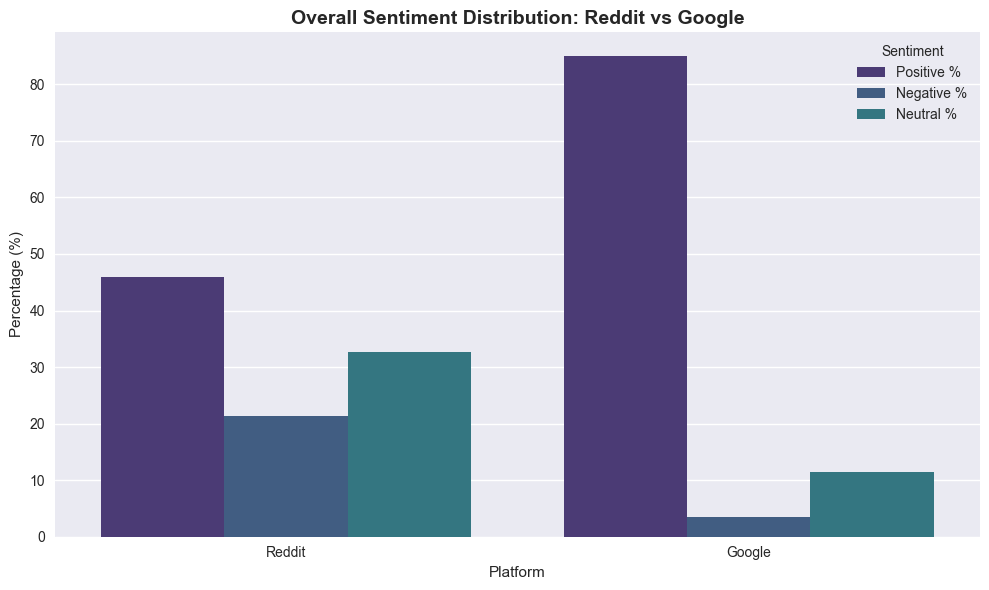

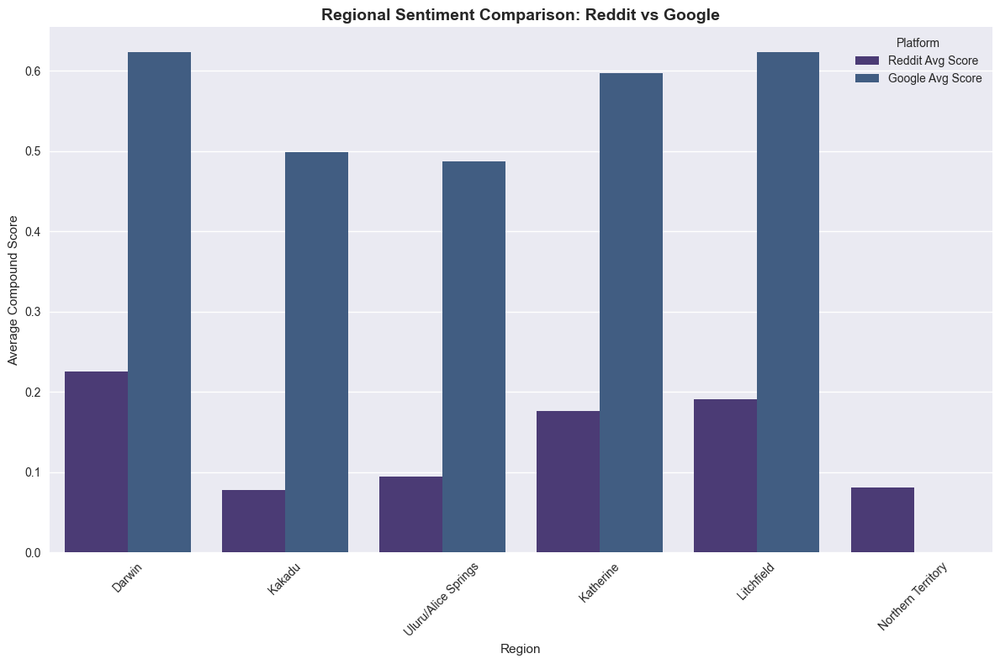

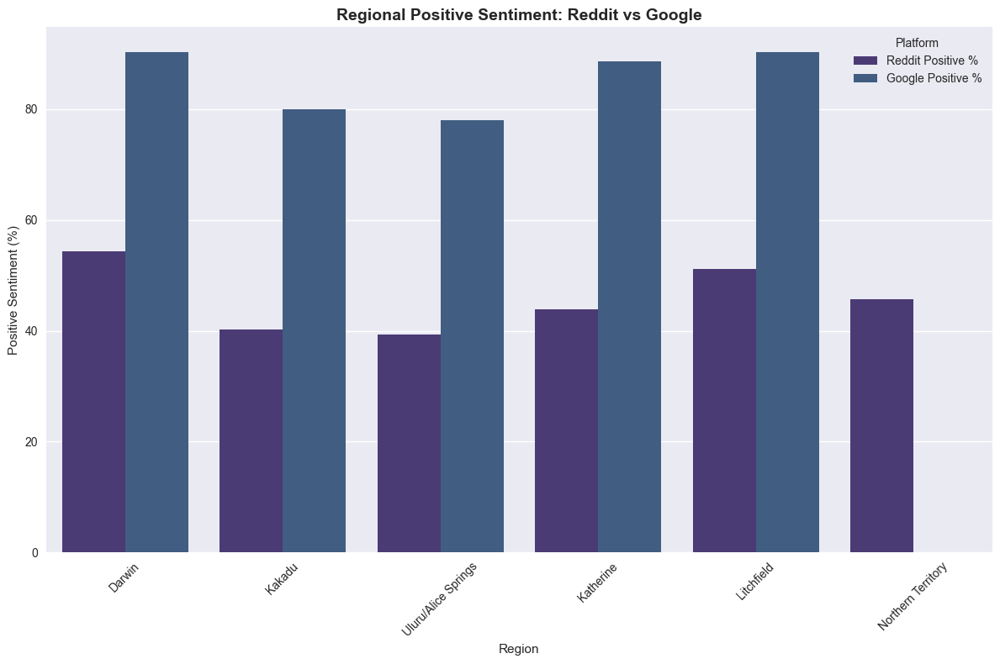

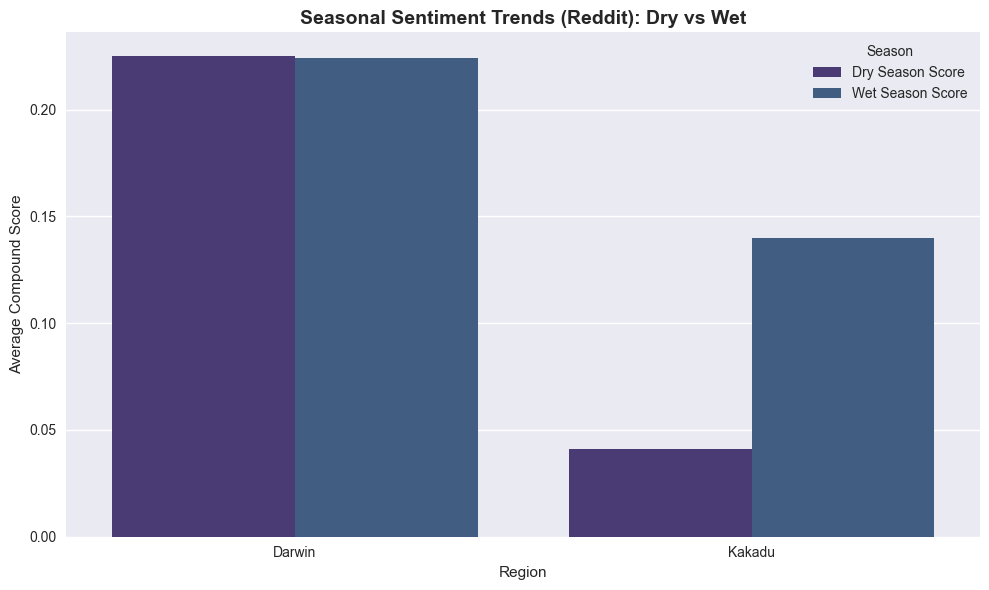

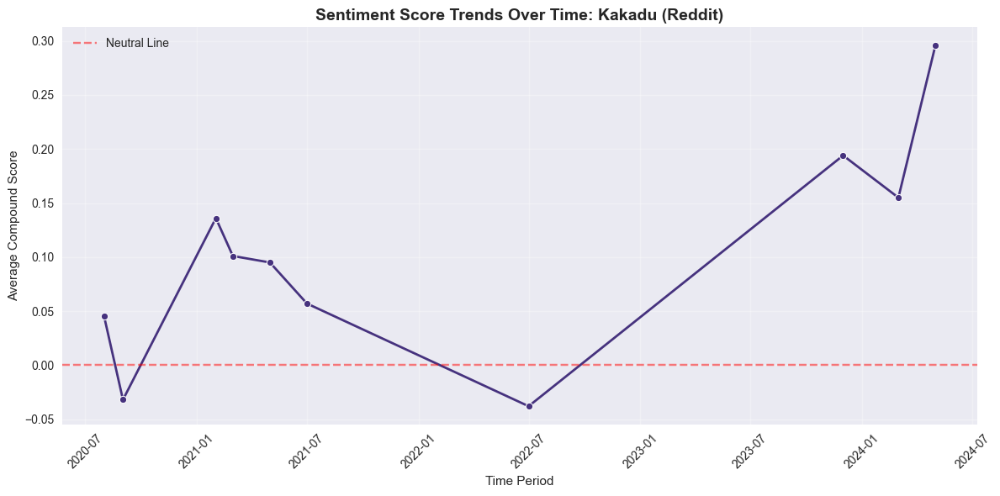

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from datetime import datetime

# Set style for better visualization
plt.style.use('seaborn')
sns.set_palette('viridis')

# Data for overall sentiment
overall_sentiment = {
    'Platform': ['Reddit', 'Google'],
    'Avg Compound Score': [0.144, 0.560],
    'Positive %': [45.92, 84.94],
    'Negative %': [21.36, 3.55],
    'Neutral %': [32.72, 11.51]
}

# Data for regional sentiment
regional_sentiment = {
    'Region': ['Darwin', 'Kakadu', 'Uluru/Alice Springs', 'Katherine', 'Litchfield', 'Northern Territory'],
    'Reddit Avg Score': [0.225, 0.078, 0.095, 0.176, 0.191, 0.081],
    'Google Avg Score': [0.623, 0.499, 0.487, 0.597, 0.623, None],  # No Google data for Northern Territory
    'Reddit Positive %': [54.42, 40.21, 39.29, 43.94, 51.21, 45.71],
    'Google Positive %': [90.29, 80.04, 77.96, 88.68, 90.29, None],
    'Reddit Negative %': [17.67, 24.87, 27.86, 14.65, 19.32, 26.67],
    'Google Negative %': [1.75, 7.20, 4.50, 2.75, 1.75, None]
}

# Data for seasonal trends (Reddit only)
seasonal_trends = {
    'Region': ['Darwin', 'Kakadu'],
    'Dry Season Score': [0.225, 0.041],
    'Wet Season Score': [0.224, 0.140]
}

# Data for time trends (Reddit, Kakadu as example)
time_trends = {
    'Month_Year': ['2020-08', '2020-09', '2021-02', '2021-03', '2021-05', '2021-07', '2022-07', '2023-12', '2024-03', '2024-05'],
    'Kakadu Sentiment': [0.045, -0.032, 0.136, 0.101, 0.095, 0.057, -0.038, 0.194, 0.155, 0.296]
}

# Convert to DataFrames
overall_df = pd.DataFrame(overall_sentiment)
regional_df = pd.DataFrame(regional_sentiment)
seasonal_df = pd.DataFrame(seasonal_trends)
time_df = pd.DataFrame(time_trends)
time_df['Month_Year'] = pd.to_datetime(time_df['Month_Year'], format='%Y-%m')

# Create Output directory if it doesn't exist
os.makedirs('Output', exist_ok=True)

# Plot 1: Overall Sentiment Comparison (Bar Plot)
plt.figure(figsize=(10, 6))
overall_melted = overall_df.melt(id_vars='Platform', value_vars=['Positive %', 'Negative %', 'Neutral %'], 
                                 var_name='Sentiment', value_name='Percentage')
sns.barplot(x='Platform', y='Percentage', hue='Sentiment', data=overall_melted)
plt.title('Overall Sentiment Distribution: Reddit vs Google', fontsize=14, fontweight='bold')
plt.xlabel('Platform')
plt.ylabel('Percentage (%)')
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

# Plot 2: Regional Sentiment Comparison (Bar Plot)
plt.figure(figsize=(12, 8))
regional_melted = regional_df.melt(id_vars='Region', value_vars=['Reddit Avg Score', 'Google Avg Score'], 
                                   var_name='Platform', value_name='Avg Compound Score')
sns.barplot(x='Region', y='Avg Compound Score', hue='Platform', data=regional_melted)
plt.title('Regional Sentiment Comparison: Reddit vs Google', fontsize=14, fontweight='bold')
plt.xlabel('Region')
plt.ylabel('Average Compound Score')
plt.xticks(rotation=45)
plt.legend(title='Platform')
plt.tight_layout()
plt.show()
# Plot 3: Regional Positive Sentiment Comparison (Bar Plot)
plt.figure(figsize=(12, 8))
positive_melted = regional_df.melt(id_vars='Region', value_vars=['Reddit Positive %', 'Google Positive %'], 
                                   var_name='Platform', value_name='Positive Percentage')
sns.barplot(x='Region', y='Positive Percentage', hue='Platform', data=positive_melted)
plt.title('Regional Positive Sentiment: Reddit vs Google', fontsize=14, fontweight='bold')
plt.xlabel('Region')
plt.ylabel('Positive Sentiment (%)')
plt.xticks(rotation=45)
plt.legend(title='Platform')
plt.tight_layout()
plt.show()

# Plot 4: Seasonal Trends Comparison (Bar Plot)
plt.figure(figsize=(10, 6))
seasonal_melted = seasonal_df.melt(id_vars='Region', value_vars=['Dry Season Score', 'Wet Season Score'], 
                                   var_name='Season', value_name='Avg Compound Score')
sns.barplot(x='Region', y='Avg Compound Score', hue='Season', data=seasonal_melted)
plt.title('Seasonal Sentiment Trends (Reddit): Dry vs Wet', fontsize=14, fontweight='bold')
plt.xlabel('Region')
plt.ylabel('Average Compound Score')
plt.legend(title='Season')
plt.tight_layout()
plt.show()

# Plot 5: Time Trends for Kakadu (Line Plot)
plt.figure(figsize=(12, 6))
sns.lineplot(x='Month_Year', y='Kakadu Sentiment', data=time_df, marker='o', linewidth=2, markersize=6)
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Neutral Line')
plt.title('Sentiment Score Trends Over Time: Kakadu (Reddit)', fontsize=14, fontweight='bold')
plt.xlabel('Time Period')
plt.ylabel('Average Compound Score')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


/var/folders/j4/64yl145x00g23vrm3rnt_zw00000gn/T/ipykernel_71747/13044312.py:102: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


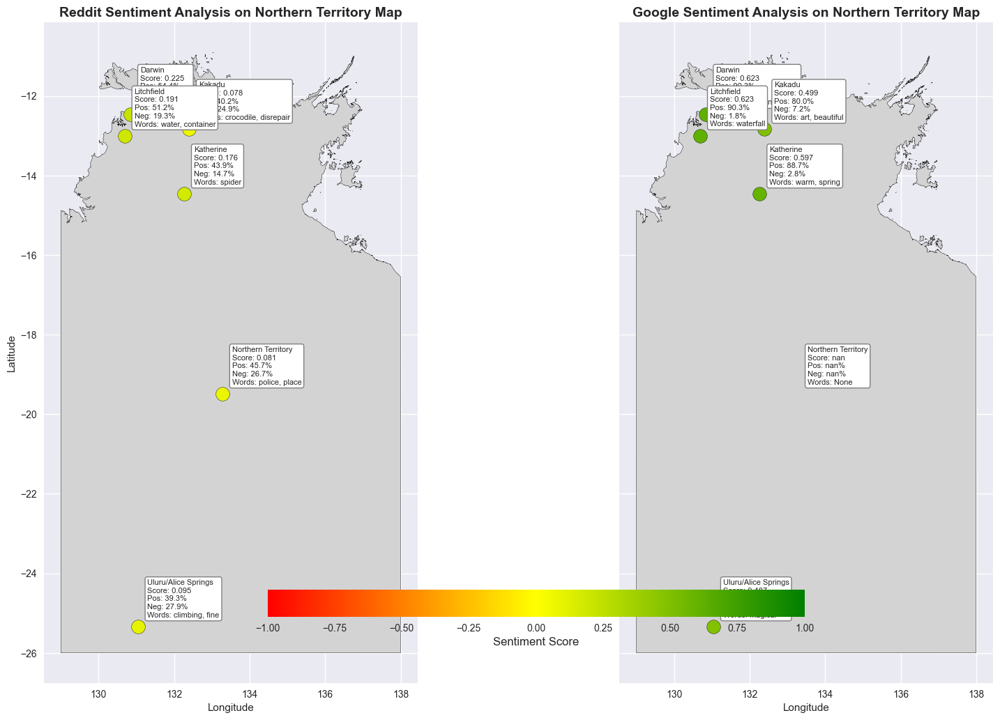

Sentiment map saved to Output/nt_sentiment_map.png


In [10]:
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
from shapely.geometry import Point
import os

# Data for sentiment analysis
data = {
    'Region': ['Darwin', 'Kakadu', 'Uluru/Alice Springs', 'Katherine', 'Litchfield', 'Northern Territory'],
    'Reddit_Sentiment': [0.225, 0.078, 0.095, 0.176, 0.191, 0.081],
    'Reddit_Positive': [54.42, 40.21, 39.29, 43.94, 51.21, 45.71],
    'Reddit_Negative': [17.67, 24.87, 27.86, 14.65, 19.32, 26.67],
    'Reddit_Key_Words': ['day, lot', 'crocodile, disrepair', 'climbing, fine', 'spider', 'water, container', 'police, place'],
    'Google_Sentiment': [0.623, 0.499, 0.487, 0.597, 0.623, None],
    'Google_Positive': [90.29, 80.04, 77.96, 88.68, 90.29, None],
    'Google_Negative': [1.75, 7.20, 4.50, 2.75, 1.75, None],
    'Google_Key_Words': ['swimming, great', 'art, beautiful', 'magical', 'warm, spring', 'waterfall', None],
    'Coordinates': [
        (130.8418, -12.4634),  # Darwin
        (132.3932, -12.8387),  # Kakadu
        (131.0369, -25.3444),  # Uluru/Alice Springs
        (132.2635, -14.4652),  # Katherine
        (130.6881, -13.0032),  # Litchfield
        (133.2752, -19.4914)   # Northern Territory (central point)
    ]
}

# Convert to DataFrame
df = pd.DataFrame(data)

# Create geometry column for points
geometry = [Point(lon, lat) for lon, lat in df['Coordinates']]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")

# Load Australia shapefile
shapefile_path = "STE_2021_AUST_SHP_GDA2020 (2)/STE_2021_AUST_GDA2020.shp"  # Replace with actual path
aus_map = gpd.read_file(shapefile_path)

# Filter for Northern Territory only (using state name or code)
# Assuming the shapefile has a column like 'STE_NAME21' for state name or 'STE_CODE21' for state code
# Northern Territory code is typically '7' or name is 'Northern Territory'
nt_map = aus_map[aus_map['STE_NAME21'] == 'Northern Territory']  # Adjust column name if different

# Ensure the CRS matches
nt_map = nt_map.to_crs("EPSG:4326")

# Create a custom colormap for sentiment scores
colors = ['red', 'yellow', 'green']
cmap = LinearSegmentedColormap.from_list('sentiment_cmap', colors, N=256)

# Create Output directory if it doesn't exist
os.makedirs('Output', exist_ok=True)

# Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10), sharex=True, sharey=True)

# Plot Reddit sentiment
nt_map.plot(ax=ax1, color='lightgrey', edgecolor='black')
for idx, row in gdf.iterrows():
    if row['Reddit_Sentiment'] is not None:
        ax1.scatter(row.geometry.x, row.geometry.y, 
                   s=200, 
                   c=[row['Reddit_Sentiment']], 
                   cmap=cmap, 
                   vmin=-1, vmax=1,
                   edgecolor='black')
        ax1.annotate(f"{row['Region']}\nScore: {row['Reddit_Sentiment']:.3f}\nPos: {row['Reddit_Positive']:.1f}%\nNeg: {row['Reddit_Negative']:.1f}%\nWords: {row['Reddit_Key_Words']}",
                    xy=(row.geometry.x, row.geometry.y),
                    xytext=(10, 10), textcoords='offset points',
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=1),
                    fontsize=8)
ax1.set_title('Reddit Sentiment Analysis on Northern Territory Map', fontsize=14, fontweight='bold')
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')

# Plot Google sentiment
nt_map.plot(ax=ax2, color='lightgrey', edgecolor='black')
for idx, row in gdf.iterrows():
    if row['Google_Sentiment'] is not None:  # Skip Northern Territory (no Google data)
        ax2.scatter(row.geometry.x, row.geometry.y, 
                   s=200, 
                   c=[row['Google_Sentiment']], 
                   cmap=cmap, 
                   vmin=-1, vmax=1,
                   edgecolor='black')
        ax2.annotate(f"{row['Region']}\nScore: {row['Google_Sentiment']:.3f}\nPos: {row['Google_Positive']:.1f}%\nNeg: {row['Google_Negative']:.1f}%\nWords: {row['Google_Key_Words']}",
                    xy=(row.geometry.x, row.geometry.y),
                    xytext=(10, 10), textcoords='offset points',
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=1),
                    fontsize=8)
ax2.set_title('Google Sentiment Analysis on Northern Territory Map', fontsize=14, fontweight='bold')
ax2.set_xlabel('Longitude')

# Add colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=-1, vmax=1))
cbar = fig.colorbar(sm, ax=[ax1, ax2], orientation='horizontal', fraction=0.05, pad=0.1)
cbar.set_label('Sentiment Score', fontsize=12)

# Adjust layout and save
plt.tight_layout()
plt.savefig('Output/nt_sentiment_map.png', dpi=300, bbox_inches='tight')
plt.show()

print("Sentiment map saved to Output/nt_sentiment_map.png")